In [14]:
import numpy as np
import pandas as pd
from scipy.stats import pearson3

# Load station coordinates
# -----------------------------
coord = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt",
    sep="\t",
)

coord.rename(
    columns={
        "HUC_02  GAGE_ID": "HUC",
        "Unnamed: 1": "GAUGE_ID",
        "Unnamed: 2": "GAUGE_NAME",
        "GAGE_NAME": "lat",
        "Unnamed: 4": "lon",
        "Unnamed: 5": "AREA",
    },
    inplace=True,
)

coord.drop(
    columns=[
        "Unnamed: 6",
        "Unnamed: 7",
        "LAT",
        "Unnamed: 9",
        "LONG",
        "Unnamed: 11",
        "DRAINAGE AREA (KM^2)",
    ],
    inplace=True,
)

coord["GAUGE_ID"] = coord["GAUGE_ID"].astype(int)



# ==========================================================
# Load forcing
# ==========================================================

forcing = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy",
    allow_pickle=True
)

print("Forcing shape:", forcing.shape)


# ==========================================================
# Variable indices
# ==========================================================

YEAR_IDX = 0
MONTH_IDX = 1
FLOW_IDX = 12
GAGE_IDX = 14


n_basins = forcing.shape[0]
n_time = forcing.shape[1]


# ==========================================================
# Output array
# ==========================================================

return_period = np.full(
    (n_basins, n_time),
    np.nan
)



# ==========================================================
# Function: Log Pearson Type III
# ==========================================================

def lp3_return_period(annual_df):

    # Remove invalid flows
    annual_df = annual_df[
        np.isfinite(annual_df["Flow"]) &
        (annual_df["Flow"] > 0)
    ].copy()


    # Need minimum years
    if len(annual_df) < 10:
        return None


    # Log10 transform
    log_flow = np.log10(
        annual_df["Flow"].values
    )


    # Pearson Type III fit
    skew, loc, scale = pearson3.fit(
        log_flow
    )


    # CDF
    probability = pearson3.cdf(
        log_flow,
        skew,
        loc,
        scale
    )


    # Exceedance probability
    exceedance = 1 - probability


    # Return period
    annual_df["Return_Period"] = (
        1 / exceedance
    )


    return annual_df



# ==========================================================
# Create gauge lookup from coord dataframe
# ==========================================================

coord_lookup = {
    int(row.GAUGE_ID): (
        row.lat,
        row.lon
    )
    for _, row in coord.iterrows()
}



# ==========================================================
# Loop through basins
# ==========================================================

for b in range(n_basins):

    print(
        f"Processing basin {b+1}/{n_basins}"
    )


    # ------------------------------
    # Extract data
    # ------------------------------

    year = forcing[b,:,YEAR_IDX].astype(int)
    month = forcing[b,:,MONTH_IDX].astype(int)

    flow = forcing[b,:,FLOW_IDX].astype(float)


    # Gauge ID
    gauge_id = int(
        forcing[b,0,GAGE_IDX]
    )


    # optional coordinate check
    if gauge_id in coord_lookup:
        lat, lon = coord_lookup[gauge_id]
    else:
        lat, lon = np.nan, np.nan



    # ------------------------------
    # Water year
    # Oct-Dec assigned next year
    # ------------------------------

    water_year = np.where(
        month >= 10,
        year + 1,
        year
    )


    # ------------------------------
    # Dataframe
    # ------------------------------

    df = pd.DataFrame(
        {
            "WaterYear": water_year,
            "Flow": flow
        }
    )


    df = df[
        np.isfinite(df.Flow)
    ]


    if len(df) == 0:
        continue



    # ------------------------------
    # Annual maximum flow
    # ------------------------------

    annual = (
        df.groupby("WaterYear")
        ["Flow"]
        .max()
        .reset_index()
    )


    annual.rename(
        columns={
            "WaterYear":"Year"
        },
        inplace=True
    )



    # ------------------------------
    # LP3 fitting
    # ------------------------------

    annual = lp3_return_period(
        annual
    )


    if annual is None:
        continue



    # ------------------------------
    # Assign return period
    # to daily data
    # ------------------------------

    for _, row in annual.iterrows():

        mask = (
            water_year == row.Year
        )


        return_period[
            b,
            mask
        ] = row.Return_Period



# ==========================================================
# Save
# ==========================================================

np.save(
    "/scratch/data/CAMELS_FORCING/CAMELS_return_period_LP3.npy",
    return_period
)


print(
    "Saved:",
    return_period.shape
)

Forcing shape: (671, 12784, 15)
Processing basin 1/671
Processing basin 2/671
Processing basin 3/671
Processing basin 4/671
Processing basin 5/671
Processing basin 6/671
Processing basin 7/671
Processing basin 8/671
Processing basin 9/671
Processing basin 10/671
Processing basin 11/671
Processing basin 12/671
Processing basin 13/671
Processing basin 14/671
Processing basin 15/671
Processing basin 16/671
Processing basin 17/671
Processing basin 18/671
Processing basin 19/671
Processing basin 20/671
Processing basin 21/671
Processing basin 22/671
Processing basin 23/671
Processing basin 24/671
Processing basin 25/671
Processing basin 26/671
Processing basin 27/671
Processing basin 28/671
Processing basin 29/671
Processing basin 30/671
Processing basin 31/671
Processing basin 32/671
Processing basin 33/671
Processing basin 34/671
Processing basin 35/671
Processing basin 36/671
Processing basin 37/671
Processing basin 38/671
Processing basin 39/671
Processing basin 40/671
Processing basin 

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import pearson3

# ==========================================================
# Load forcing
# ==========================================================

forcing = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy",
    allow_pickle=True
)

print("Forcing shape:", forcing.shape)

# ==========================================================
# Variable indices
# ==========================================================

YEAR_IDX = 0
MONTH_IDX = 1
FLOW_IDX = 12
GAGE_IDX = 14

n_basins = forcing.shape[0]

# Return periods to calculate
return_periods = [5, 10, 25, 50, 100]

# ==========================================================
# Output dataframe
# ==========================================================

results = []

# ==========================================================
# Loop over basins
# ==========================================================

for b in range(n_basins):

    print(f"Processing basin {b+1}/{n_basins}")

    year = forcing[b, :, YEAR_IDX].astype(int)
    month = forcing[b, :, MONTH_IDX].astype(int)
    flow = forcing[b, :, FLOW_IDX].astype(float)

    gauge_id = int(forcing[b, 0, GAGE_IDX])

    # -------------------------
    # Water year
    # -------------------------

    water_year = np.where(month >= 10, year + 1, year)

    df = pd.DataFrame({
        "WaterYear": water_year,
        "Flow": flow
    })

    df = df[
        np.isfinite(df["Flow"]) &
        (df["Flow"] > 0)
    ]

    if len(df) == 0:
        continue

    # -------------------------
    # Annual maxima
    # -------------------------

    annual = (
        df.groupby("WaterYear")["Flow"]
        .max()
        .reset_index()
    )

    # Require enough years
    if len(annual) < 10:
        continue

    # -------------------------
    # Fit LP3
    # -------------------------

    log_flow = np.log10(annual["Flow"].values)

    skew, loc, scale = pearson3.fit(log_flow)

    basin_result = {
        "Gauge_ID": gauge_id,
        "Num_Years": len(annual)
    }

    # -------------------------
    # Compute flood magnitudes
    # -------------------------

    for T in return_periods:

        p = 1 - 1 / T

        log_q = pearson3.ppf(
            p,
            skew,
            loc,
            scale
        )

        q = 10 ** log_q

        basin_result[f"Q_{T}yr"] = q

    results.append(basin_result)

# ==========================================================
# Save
# ==========================================================

results = pd.DataFrame(results)
# Basin area from CAMELS metadata
coord = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/basin_dataset_public_v1p2/basin_metadata/gauge_information.txt",
    sep="\t",
)

coord.rename(
    columns={
        "HUC_02  GAGE_ID": "HUC",
        "Unnamed: 1": "Gauge_ID",
        "Unnamed: 2": "GAUGE_NAME",
        "GAGE_NAME": "lat",
        "Unnamed: 4": "lon",
        "Unnamed: 5": "AREA"
    },
    inplace=True,
)

coord = coord[["Gauge_ID", "AREA"]]
coord["Gauge_ID"] = coord["Gauge_ID"].astype(int)

# Merge area
results = results.merge(coord, on="Gauge_ID", how="left")

# Conversion factor
factor = 2.446575

# Convert thresholds
for T in [5, 10, 25, 50, 100]:
    results[f"Q_{T}yr"] = factor * results[f"Q_{T}yr"] / results["AREA"]

# Save
# df.to_csv(
#     "/scratch/data/CAMELS_FORCING/CAMELS_LP3_flood_thresholds_mmday.csv",
#     index=False
# )

# print(df.head())

results.to_csv(
    "/scratch/data/CAMELS_FORCING/CAMELS_LP3_flood_thresholds_mmday.csv",
    index=False
)

# print(results.head())
print("Saved:", results.shape)
display(results)


Forcing shape: (671, 12784, 15)
Processing basin 1/671
Processing basin 2/671
Processing basin 3/671
Processing basin 4/671
Processing basin 5/671
Processing basin 6/671
Processing basin 7/671
Processing basin 8/671
Processing basin 9/671
Processing basin 10/671
Processing basin 11/671
Processing basin 12/671
Processing basin 13/671
Processing basin 14/671
Processing basin 15/671
Processing basin 16/671
Processing basin 17/671
Processing basin 18/671
Processing basin 19/671
Processing basin 20/671
Processing basin 21/671
Processing basin 22/671
Processing basin 23/671
Processing basin 24/671
Processing basin 25/671
Processing basin 26/671
Processing basin 27/671
Processing basin 28/671
Processing basin 29/671
Processing basin 30/671
Processing basin 31/671
Processing basin 32/671
Processing basin 33/671
Processing basin 34/671
Processing basin 35/671
Processing basin 36/671
Processing basin 37/671
Processing basin 38/671
Processing basin 39/671
Processing basin 40/671
Processing basin 

,Gauge_ID,Num_Years,Q_5yr,Q_10yr,Q_25yr,Q_50yr,Q_100yr,AREA
0,1013500,35,11.182103,12.965045,15.391430,17.328970,19.381481,2252.70
1,1022500,35,21.200616,24.747239,29.160079,32.405469,35.620769,573.60
2,1030500,35,13.984996,15.200603,16.350640,17.003151,17.526520,3676.17
3,1031500,35,36.630383,45.212410,56.656137,65.588215,74.851407,769.05
4,1047000,36,36.038342,43.512834,53.202616,60.583640,68.095274,909.10
...,...,...,...,...,...,...,...,...
666,14309500,36,55.740071,63.764088,71.908063,76.805245,80.902524,224.92
667,14316700,36,53.534684,60.111118,66.248766,69.642811,72.290016,587.90
668,14325000,36,78.997082,88.514680,97.741028,103.060090,107.364378,443.07
669,14362250,33,7.485997,11.613936,17.997145,23.498767,29.554735,41.42


In [16]:
import numpy as np
import pandas as pd
import os
import shutil
# -----------------------------
# Load data properly
# -----------------------------
forcings = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671_eckhardt_mmday.npy"
)


df = pd.read_csv("/scratch/data/CAMELS_531.csv")
df["Gauge ID"] = df["Gauge ID"].astype(str).str.zfill(8)

# Gauge IDs from forcing
gauge_id = forcings[:, 0, -2].astype(int).astype(str)
gauge_id = np.char.zfill(gauge_id, 8)

all_idx = np.arange(forcings.shape[0])

# -----------------------------
# PUR regions
# -----------------------------
regionDivide = [
    [1, 2],
    [3, 6],
    [4, 5, 7],
    [9, 10],
    [8, 11, 12, 13],
    [14, 15, 16, 18],
    [17]
]

base_filename = "CAMELS_return_period_LP3.npy"
attr_filename = "daymet_19800101_20141231_attr_671.npy"


root = "/scratch/data/PUR_DATA/"


flood= np.load("/scratch/data/CAMELS_FORCING/CAMELS_return_period_LP3.npy")

for i, hucs in enumerate(regionDivide, start=1):

    # -----------------------------
    # TEST indices (531 subset)
    # -----------------------------
    region_gauges = df[df["HUC"].isin(hucs)]["Gauge ID"].values
    test_idx = np.where(np.isin(gauge_id, region_gauges))[0]

    # -----------------------------
    # TRAIN indices (671 full set minus test)
    # -----------------------------
    train_idx = np.setdiff1d(all_idx, test_idx)

    # -----------------------------
    # Split forcing
    # -----------------------------
    train_flood = flood[train_idx]
    test_flood = flood[test_idx]

    # -----------------------------
    # Directories
    # -----------------------------
    train_dir = os.path.join(root, "train", f"Region_{i}")
    test_dir  = os.path.join(root, "test", f"Region_{i}")

    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(test_dir, exist_ok=True)

    # -----------------------------
    # Save forcing
    # -----------------------------
    np.save(os.path.join(train_dir, base_filename), train_flood)
    np.save(os.path.join(test_dir, base_filename), test_flood)

    # -----------------------------

    # --

    print(
        f"Region {i}: "
        f"Train={train_flood.shape[0]}, Test={test_flood.shape[0]}"
    )

Region 1: Train=579, Test=92
Region 2: Train=576, Test=95
Region 3: Train=578, Test=93
Region 4: Train=620, Test=51
Region 5: Train=603, Test=68
Region 6: Train=611, Test=60
Region 7: Train=599, Test=72


In [ ]:
method= 'Furey'

## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

flood= np.load("/scratch/data/PUR_DATA/test/Region_1/CAMELS_return_period_LP3.npy")
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'PRMS', 'HBV_capillary']

if model=='HBV':
    dyn= 'parBETA_parBETAET_'

if model=='marrmot_PRMS':
    dyn= 'alpha_cgw_scx_tt_'

if model=='HBV_capillary':
    dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    folder= f'/home/s0shar47/scratch/OUTPUTS_{test}_{objectives[1]}/{model}/1/'
    sfolder= f'/home/s0shar47/scratch/OUTPUTS_{test}_{objectives[0]}/{model}/1/'
    gauge = np.load(
        "/home/s0shar47/scratch/BASEFLOW_FOLDS/1/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
 

if test== 'PUR':
    folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_1/"
    sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_{objectives[0]}/Region_1/"
    gauge= np.load(f"/scratch/data/PUR_DATA/test/Region_1/daymet_19800101_20141231_forcing_671_baseflow_mmday.npy")


import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import matplotlib.dates as mdates
import os


# ==========================================================
# NSE function
# ==========================================================
def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)

    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den



# ==========================================================
# Load observed and simulated streamflow
# ==========================================================

ob_flow = np.load(
    os.path.join(
        folder,
        f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"{dyn}/ts1989_1999/00060_Mean.npy"
    )
)


sim_flow_old = np.load(
    os.path.join(
        sfolder,
        f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"{dyn}/ts1989_1999/flow_sim.npy"
    )
)


sim_flow_new = np.load(
    os.path.join(
        folder,
        f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        f"{dyn}/ts1989_1999/flow_sim.npy"
    )
)


sim_flow_old = np.squeeze(sim_flow_old)
sim_flow_new = np.squeeze(sim_flow_new)


print("Observed shape :", ob_flow.shape)
print("Single shape   :", sim_flow_old.shape)
print("Multi shape    :", sim_flow_new.shape)



# ==========================================================
# Align flood return period with LSTM prediction period
# ==========================================================

# Full flood record
flood_dates = pd.date_range(
    start="1980-01-01",
    end="2014-12-31",
    freq="D"
)


# LSTM prediction dates
dates = pd.date_range(
    start="1990-10-01",
    periods=ob_flow.shape[0],
    freq="D"
)


# Find matching flood index
start_idx = np.where(
    flood_dates == dates[0]
)[0][0]


end_idx = start_idx + len(dates)


# Extract flood period corresponding to predictions
flood_test = flood[:, start_idx:end_idx]


print("\nAligned data")
print("Flood shape :", flood_test.shape)
print("Obs shape   :", ob_flow.shape)


assert flood_test.shape[1] == ob_flow.shape[0]



# ==========================================================
# Find first 5 basins with >50-year flood
# ==========================================================

selected_basins = []


for basin in range(flood_test.shape[0]):

    extreme_days = np.where(
        flood_test[basin] > 50
    )[0]


    if len(extreme_days) == 0:
        continue


    # Largest return period event
    peak_day = extreme_days[
        np.argmax(
            flood_test[basin, extreme_days]
        )
    ]


    peak_date = dates[peak_day]

    selected_basins.append(
        (
            basin,
            peak_date,
            peak_day,
            flood_test[basin, peak_day]
        )
    )


    if len(selected_basins) == 10:
        break



print("\nSelected basins")

for basin, date, _, rp in selected_basins:

    gid = int(gauge[basin,0,-2])

    print(
        f"Basin {basin} | "
        f"Gauge {gid} | "
        f"Date {date.date()} | "
        f"Return period {rp:.2f} years"
    )



# ==========================================================
# Plot hydrological year October - September
# ==========================================================

for basin, peak_date, peak_day, peak_rp in selected_basins:


    gid = int(gauge[basin,0,-2])


    # -----------------------------------------
    # Determine water year
    # October starts hydrological year
    # -----------------------------------------

    if peak_date.month >= 10:
        hydro_year = peak_date.year
    else:
        hydro_year = peak_date.year - 1



    # October -> September mask
    mask = (
        ((dates.year == hydro_year) &
         (dates.month >= 10))
        |
        ((dates.year == hydro_year + 1) &
         (dates.month <= 9))
    )


    plot_dates = dates[mask]


    obs = ob_flow[mask, basin].copy()

    sim_old = sim_flow_old[mask, basin].copy()

    sim_new = sim_flow_new[mask, basin].copy()

    rp = flood_test[basin, mask].copy()



    # NSE
    nse_single = calc_nse(
        obs,
        sim_old
    )

    nse_multi = calc_nse(
        obs,
        sim_new
    )



    # For log scale
    obs_plot = obs.copy()
    sim_old_plot = sim_old.copy()
    sim_new_plot = sim_new.copy()


    obs_plot[obs_plot <= 0] = np.nan
    sim_old_plot[sim_old_plot <= 0] = np.nan
    sim_new_plot[sim_new_plot <= 0] = np.nan



    fig, ax1 = plt.subplots(
        figsize=(15,5)
    )


    # ==================================================
    # Streamflow
    # ==================================================

    ax1.scatter(
        plot_dates,
        obs_plot,
        color="black",
        s=10,
        label="Observed Flow",
        zorder=5
    )


    ax1.plot(
        plot_dates,
        sim_old_plot,
        color="red",
        linewidth=1.5,
        label=f"Single Objective NSE={nse_single:.3f}"
    )


    ax1.plot(
        plot_dates,
        sim_new_plot,
        color="blue",
        linewidth=1.5,
        label=f"Multi Objective NSE={nse_multi:.3f}"
    )


    ax1.set_yscale("log")

    ax1.set_ylabel(
        "Flow (mm/day)",
        fontsize=14
    )



    # ==================================================
    # Return period
    # ==================================================

    ax2 = ax1.twinx()


    ax2.plot(
        plot_dates,
        rp,
        color="green",
        linewidth=2,
        label="Return Period"
    )


    ax2.axhline(
        50,
        color="green",
        linestyle="--",
        linewidth=1.5,
        label="50-year threshold"
    )


    ax2.set_ylabel(
        "Return Period (years)",
        fontsize=14
    )



    # ==================================================
    # Formatting
    # ==================================================

    ax1.set_title(
        f"{model} | {test}\n"
        f"Gauge {gid} | Water Year {hydro_year}-{hydro_year+1}\n"
        f"Peak Return Period = {peak_rp:.1f} years",
        fontsize=15
    )


    ax1.xaxis.set_major_locator(
        mdates.MonthLocator(interval=2)
    )

    ax1.xaxis.set_major_formatter(
        mdates.DateFormatter("%Y-%b")
    )


    plt.xticks(rotation=45)


    ax1.grid(
        True,
        alpha=0.3
    )


    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()

    lines2, labels2 = ax2.get_legend_handles_labels()


    ax1.legend(
        lines1 + lines2,
        labels1 + labels2,
        loc="upper left",
        fontsize=10
    )


    plt.tight_layout()

    plt.show()

Number of basin-years with return period > 50 years: 648


In [ ]:
import numpy as np
import pandas as pd
import os


# ==========================================================
# SETTINGS
# ==========================================================

method = "Furey"

model = "HBV"

if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marmmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"



# ==========================================================
# NSE FUNCTION
# ==========================================================

def calc_nse(obs, sim):

    mask = (
        np.isfinite(obs) &
        np.isfinite(sim)
    )

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    denominator = np.sum(
        (obs - np.mean(obs)) ** 2
    )

    if denominator == 0:
        return np.nan

    return (
        1 -
        np.sum((obs - sim) ** 2)
        /
        denominator
    )



# ==========================================================
# STORAGE FOR ALL REGIONS
# ==========================================================

obs_all = []
single_all = []
multi_all = []

total_events = 0



# ==========================================================
# LOOP REGIONS 1-7
# ==========================================================

for region in range(1,8):

    print("\n" + "="*70)
    print(f"Processing Region {region}")
    print("="*70)


    # ------------------------------------------------------
    # Files
    # ------------------------------------------------------

    flood_file = (
        f"/scratch/data/PUR_DATA/test/"
        f"Region_{region}/"
        f"CAMELS_return_period_LP3.npy"
    )


    forcing_file = (
        f"/scratch/data/PUR_DATA/test/"
        f"Region_{region}/"
        f"daymet_19800101_20141231_forcing_671_baseflow_mmday.npy"
    )


    folder = (
        f"/home/s0shar47/scratch/"
        f"OUTPUTS_Paper1/PUR/"
        f"{method}_Multi/"
        f"Region_{region}/"
    )


    sfolder = (
        f"/home/s0shar47/scratch/"
        f"OUTPUTS_Paper1/PUR/"
        f"OUTPUTS_PUR_Single/"
        f"Region_{region}/"
    )


    # ------------------------------------------------------
    # Load return period
    # ------------------------------------------------------

    flood = np.load(
        flood_file
    )


    gauge = np.load(
        forcing_file
    )


    # ------------------------------------------------------
    # Load observations
    # ------------------------------------------------------

    model_folder = (
        f"LSTM_{model}_E50_R365_B100_H256_"
        f"tr1989_1999_n16_111111/"
    )


    ob_flow = np.load(
        os.path.join(
            folder,
            model_folder,
            dyn,
            "ts1989_1999",
            "00060_Mean.npy"
        )
    )


    sim_multi = np.load(
        os.path.join(
            folder,
            model_folder,
            dyn,
            "ts1989_1999",
            "flow_sim.npy"
        )
    )


    sim_single = np.load(
        os.path.join(
            sfolder,
            model_folder,
            dyn,
            "ts1989_1999",
            "flow_sim.npy"
        )
    )


    sim_multi = np.squeeze(sim_multi)
    sim_single = np.squeeze(sim_single)



    print("Obs:", ob_flow.shape)
    print("Single:", sim_single.shape)
    print("Multi:", sim_multi.shape)



    # ------------------------------------------------------
    # Dates
    # ------------------------------------------------------

    flood_dates = pd.date_range(
        start="1980-01-01",
        end="2014-12-31",
        freq="D"
    )


    dates = pd.date_range(
        start="1990-10-01",
        periods=ob_flow.shape[0],
        freq="D"
    )



    # ------------------------------------------------------
    # Align return period
    # ------------------------------------------------------

    start_idx = np.where(
        flood_dates == dates[0]
    )[0][0]


    end_idx = (
        start_idx +
        len(dates)
    )


    flood_test = flood[
        :,
        start_idx:end_idx
    ]


    assert (
        flood_test.shape[1]
        ==
        len(dates)
    )



    # ------------------------------------------------------
    # Water year
    # ------------------------------------------------------

    water_year = np.where(
        dates.month >= 10,
        dates.year,
        dates.year-1
    )


    region_events = 0



    # ------------------------------------------------------
    # Find >50 year floods
    # ------------------------------------------------------

    for basin in range(
        flood_test.shape[0]
    ):


        annual_rp = (
            pd.DataFrame(
                {
                    "WY": water_year,
                    "RP": flood_test[basin]
                }
            )
            .groupby("WY")
            ["RP"]
            .first()
        )


        extreme_years = annual_rp[
            annual_rp > 50
        ].index.values



        region_events += len(
            extreme_years
        )



        # --------------------------------------------------
        # Extract hydrological years
        # --------------------------------------------------

        for wy in extreme_years:


            mask = (
                (
                    (dates.year == wy)
                    &
                    (dates.month >= 10)
                )
                |
                (
                    (dates.year == wy+1)
                    &
                    (dates.month <= 9)
                )
            )


            obs_all.append(
                ob_flow[mask, basin]
            )


            single_all.append(
                sim_single[mask, basin]
            )


            multi_all.append(
                sim_multi[mask, basin]
            )


    total_events += region_events


    print(
        f"Region {region} "
        f">50 year basin-years: {region_events}"
    )



# ==========================================================
# Combine all regions
# ==========================================================

obs_all = np.concatenate(
    obs_all
)

single_all = np.concatenate(
    single_all
)

multi_all = np.concatenate(
    multi_all
)



print("\n")
print("="*70)
print("FINAL RESULTS (REGIONS 1-7)")
print("="*70)

print(
    "Total basin-years:",
    total_events
)

print(
    "Total daily samples:",
    len(obs_all)
)



# ==========================================================
# Metrics
# ==========================================================

nse_single = calc_nse(
    obs_all,
    single_all
)


nse_multi = calc_nse(
    obs_all,
    multi_all
)



rmse_single = np.sqrt(
    np.mean(
        (obs_all-single_all)**2
    )
)


rmse_multi = np.sqrt(
    np.mean(
        (obs_all-multi_all)**2
    )
)



bias_single = (
    np.sum(single_all-obs_all)
    /
    np.sum(obs_all)
)


bias_multi = (
    np.sum(multi_all-obs_all)
    /
    np.sum(obs_all)
)



print("\nNSE")
print(
    f"Single objective : {nse_single:.4f}"
)

print(
    f"Multi objective  : {nse_multi:.4f}"
)


print("\nRMSE")
print(
    f"Single objective : {rmse_single:.4f}"
)

print(
    f"Multi objective  : {rmse_multi:.4f}"
)


print("\nRelative Bias")
print(
    f"Single objective : {bias_single:.4f}"
)

print(
    f"Multi objective  : {bias_multi:.4f}"
)


Processing Region 1
Obs: (3286, 92)
Single: (3286, 92)
Multi: (3286, 92)
Region 1 >50 year basin-years: 29

Processing Region 2
Obs: (3286, 95)
Single: (3286, 95)
Multi: (3286, 95)
Region 2 >50 year basin-years: 35

Processing Region 3
Obs: (3286, 93)
Single: (3286, 93)
Multi: (3286, 93)
Region 3 >50 year basin-years: 29

Processing Region 4
Obs: (3286, 51)
Single: (3286, 51)
Multi: (3286, 51)
Region 4 >50 year basin-years: 21

Processing Region 5
Obs: (3286, 68)
Single: (3286, 68)
Multi: (3286, 68)
Region 5 >50 year basin-years: 26

Processing Region 6
Obs: (3286, 60)
Single: (3286, 60)
Multi: (3286, 60)
Region 6 >50 year basin-years: 30

Processing Region 7
Obs: (3286, 72)
Single: (3286, 72)
Multi: (3286, 72)
Region 7 >50 year basin-years: 36


FINAL RESULTS (REGIONS 1-7)
Total basin-years: 206
Total daily samples: 75246

NSE
Single objective : 0.7096
Multi objective  : 0.7104

RMSE
Single objective : 3.8519
Multi objective  : 3.8464

Relative Bias
Single objective : -0.0678
Multi o

In [5]:
import numpy as np
import pandas as pd
import os

method = "Furey"

model = "HBV"

if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"

# ==========================================================
# METRIC FUNCTIONS
# ==========================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum(
        (obs - np.mean(obs))**2
    )

    if den == 0:
        return np.nan

    return (
        1 -
        np.sum((obs-sim)**2)
        /
        den
    )



def calc_kge(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan


    r = np.corrcoef(
        obs,
        sim
    )[0,1]


    std_obs = np.std(obs)
    std_sim = np.std(sim)


    if std_obs == 0:
        return np.nan


    alpha = std_sim/std_obs


    mean_obs = np.mean(obs)

    if mean_obs == 0:
        return np.nan


    beta = np.mean(sim)/mean_obs


    return (
        1 -
        np.sqrt(
            (r-1)**2 +
            (alpha-1)**2 +
            (beta-1)**2
        )
    )



def calc_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]


    den = np.sum(obs)

    if den == 0:
        return np.nan


    return (
        np.sum(sim)-den
    ) / den



def calc_abs_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]


    den = np.sum(obs)

    if den == 0:
        return np.nan


    return np.abs(
        np.sum(sim)-den
    ) / den



# ==========================================================
# RETURN PERIOD THRESHOLDS
# ==========================================================

thresholds = [
    10,
    25,
    50,
    100
]


# storage
results = {}



# ==========================================================
# Loop thresholds
# ==========================================================

for threshold in thresholds:


    # print("\n")
    # print("="*70)
    # print(
    #     f"Return Period > {threshold} years"
    # )
    # print("="*70)


    obs_all = []
    single_all = []
    multi_all = []

    event_count = 0



    # ------------------------------------------------------
    # Loop regions
    # ------------------------------------------------------

    for region in range(1,8):


        flood = np.load(
            f"/scratch/data/PUR_DATA/test/"
            f"Region_{region}/"
            f"CAMELS_return_period_LP3.npy"
        )


        folder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"{method}_Multi/"
            f"Region_{region}/"
        )


        sfolder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/"
            f"Region_{region}/"
        )



        model_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_"
            f"tr1989_1999_n16_111111/"
        )


        obs = np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1989_1999",
                "00060_Mean.npy"
            )
        )


        sim_multi = np.squeeze(
            np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1989_1999",
                    "flow_sim.npy"
                )
            )
        )


        sim_single = np.squeeze(
            np.load(
                os.path.join(
                    sfolder,
                    model_folder,
                    dyn,
                    "ts1989_1999",
                    "flow_sim.npy"
                )
            )
        )



        flood_dates = pd.date_range(
            "1980-01-01",
            "2014-12-31",
            freq="D"
        )


        dates = pd.date_range(
            "1989-10-01",
            periods=obs.shape[0],
            freq="D"
        )


        start = np.where(
            flood_dates == dates[0]
        )[0][0]


        flood = flood[:,start:start+len(dates)]



        water_year = np.where(
            dates.month >= 10,
            dates.year,
            dates.year-1
        )



        for basin in range(
            flood.shape[0]
        ):


            annual = (
                pd.DataFrame(
                    {
                        "WY":water_year,
                        "RP":flood[basin]
                    }
                )
                .groupby("WY")
                ["RP"]
                .first()
            )


            extreme_years = annual[
                annual > threshold
            ].index.values


            event_count += len(
                extreme_years
            )



            for wy in extreme_years:


                mask = (
                    (
                    (dates.year==wy)
                    &
                    (dates.month>=10)
                    )
                    |
                    (
                    (dates.year==wy+1)
                    &
                    (dates.month<=9)
                    )
                )


                obs_all.append(
                    obs[mask,basin]
                )

                single_all.append(
                    sim_single[mask,basin]
                )

                multi_all.append(
                    sim_multi[mask,basin]
                )



    # ------------------------------------------------------
    # Combine all events
    # ------------------------------------------------------

    obs_all = np.concatenate(obs_all)

    single_all = np.concatenate(single_all)

    multi_all = np.concatenate(multi_all)



    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    results[threshold] = {

        "Events": event_count,

        "Single NSE":
            calc_nse(obs_all,single_all),

        "Multi NSE":
            calc_nse(obs_all,multi_all),


        "Single KGE":
            calc_kge(obs_all,single_all),

        "Multi KGE":
            calc_kge(obs_all,multi_all),


        "Single Bias":
            calc_bias(obs_all,single_all),

        "Multi Bias":
            calc_bias(obs_all,multi_all),


        "Single Abs Bias":
            calc_abs_bias(obs_all,single_all),

        f"Multi Abs Bias":
            calc_abs_bias(obs_all,multi_all),


        "Samples":
            len(obs_all)
    }



# ==========================================================
# Print summary table
# ==========================================================

summary = pd.DataFrame(results).T

# print("\nFINAL RESULTS")
print(method, model,'(1989 to 1999)')
summary

Furey HBV (1989 to 1999)


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
10,661.0,0.750834,0.747652,0.826089,0.808375,-0.036568,-0.060421,0.036568,0.060421,241401.0
25,321.0,0.750965,0.749536,0.823972,0.805140,-0.020685,-0.049814,0.020685,0.049814,117245.0
50,208.0,0.741401,0.744094,0.813318,0.802096,-0.020955,-0.052718,0.020955,0.052718,75981.0
100,105.0,0.728864,0.728101,0.790527,0.783596,-0.020988,-0.044955,0.020988,0.044955,38360.0


In [6]:
import numpy as np
import pandas as pd
import os

method = "Furey"

model = "HBV"

if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"

# ==========================================================
# METRIC FUNCTIONS
# ==========================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum(
        (obs - np.mean(obs))**2
    )

    if den == 0:
        return np.nan

    return (
        1 -
        np.sum((obs-sim)**2)
        /
        den
    )



def calc_kge(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan


    r = np.corrcoef(
        obs,
        sim
    )[0,1]


    std_obs = np.std(obs)
    std_sim = np.std(sim)


    if std_obs == 0:
        return np.nan


    alpha = std_sim/std_obs


    mean_obs = np.mean(obs)

    if mean_obs == 0:
        return np.nan


    beta = np.mean(sim)/mean_obs


    return (
        1 -
        np.sqrt(
            (r-1)**2 +
            (alpha-1)**2 +
            (beta-1)**2
        )
    )



def calc_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]


    den = np.sum(obs)

    if den == 0:
        return np.nan


    return (
        np.sum(sim)-den
    ) / den



def calc_abs_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]


    den = np.sum(obs)

    if den == 0:
        return np.nan


    return np.abs(
        np.sum(sim)-den
    ) / den



# ==========================================================
# RETURN PERIOD THRESHOLDS
# ==========================================================

thresholds = [
    10,
    25,
    50,
    100
]


# storage
results = {}



# ==========================================================
# Loop thresholds
# ==========================================================

for threshold in thresholds:


    # print("\n")
    # print("="*70)
    # print(
    #     f"Return Period > {threshold} years"
    # )
    # print("="*70)


    obs_all = []
    single_all = []
    multi_all = []

    event_count = 0



    # ------------------------------------------------------
    # Loop regions
    # ------------------------------------------------------

    for region in range(1,8):


        flood = np.load(
            f"/scratch/data/PUR_DATA/test/"
            f"Region_{region}/"
            f"CAMELS_return_period_LP3.npy"
        )


        folder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"{method}_Multi/"
            f"Region_{region}/"
        )


        sfolder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/"
            f"Region_{region}/"
        )



        model_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_"
            f"tr1989_1999_n16_111111/"
        )


        obs = np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1980_2014",
                "00060_Mean.npy"
            )
        )


        sim_multi = np.squeeze(
            np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )


        sim_single = np.squeeze(
            np.load(
                os.path.join(
                    sfolder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )



        flood_dates = pd.date_range(
            "1980-01-01",
            "2014-12-31",
            freq="D"
        )


        dates = pd.date_range(
            "1980-01-01",
            periods=obs.shape[0],
            freq="D"
        )


        start = np.where(
            flood_dates == dates[0]
        )[0][0]


        flood = flood[:,start:start+len(dates)]



        water_year = np.where(
            dates.month >= 10,
            dates.year,
            dates.year-1
        )



        for basin in range(
            flood.shape[0]
        ):


            annual = (
                pd.DataFrame(
                    {
                        "WY":water_year,
                        "RP":flood[basin]
                    }
                )
                .groupby("WY")
                ["RP"]
                .first()
            )


            extreme_years = annual[
                annual > threshold
            ].index.values


            event_count += len(
                extreme_years
            )



            for wy in extreme_years:


                mask = (
                    (
                    (dates.year==wy)
                    &
                    (dates.month>=10)
                    )
                    |
                    (
                    (dates.year==wy+1)
                    &
                    (dates.month<=9)
                    )
                )


                obs_all.append(
                    obs[mask,basin]
                )

                single_all.append(
                    sim_single[mask,basin]
                )

                multi_all.append(
                    sim_multi[mask,basin]
                )



    # ------------------------------------------------------
    # Combine all events
    # ------------------------------------------------------

    obs_all = np.concatenate(obs_all)

    single_all = np.concatenate(single_all)

    multi_all = np.concatenate(multi_all)



    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    results[threshold] = {

        "Events": event_count,

        "Single NSE":
            calc_nse(obs_all,single_all),

        "Multi NSE":
            calc_nse(obs_all,multi_all),


        "Single KGE":
            calc_kge(obs_all,single_all),

        "Multi KGE":
            calc_kge(obs_all,multi_all),


        "Single Bias":
            calc_bias(obs_all,single_all),

        "Multi Bias":
            calc_bias(obs_all,multi_all),


        "Single Abs Bias":
            calc_abs_bias(obs_all,single_all),

        f"Multi Abs Bias":
            calc_abs_bias(obs_all,multi_all),


        "Samples":
            len(obs_all)
    }



# ==========================================================
# Print summary table
# ==========================================================

summary = pd.DataFrame(results).T

# print("\nFINAL RESULTS")
print(method, model,'(1980 to 2014)')
summary

Furey HBV (1980 to 2014)


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
10,1814.0,0.557234,0.557975,0.656571,0.649035,-0.006161,-0.028946,0.006161,0.028946,651681.0
25,821.0,0.652786,0.655689,0.745650,0.737512,-0.023929,-0.045671,0.023929,0.045671,297872.0
50,518.0,0.608251,0.613140,0.699358,0.696239,-0.020022,-0.042391,0.020022,0.042391,187937.0
100,271.0,0.546907,0.551933,0.641099,0.640063,-0.003238,-0.021497,0.003238,0.021497,98361.0


In [ ]:
import numpy as np
import pandas as pd
import os

method = "Furey"
model = "HBV"

if model == "HBV":
    dyn = "parBETA_parBETAET_"
elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"
elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"

# ==========================================================
# METRIC FUNCTIONS
# ==========================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)

    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)

    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


def calc_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)

    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)

    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


# ==========================================================
# RETURN PERIOD THRESHOLDS
# ==========================================================

thresholds = [10, 25, 50, 100]

results = {}

# ==========================================================
# LOOP OVER THRESHOLDS
# ==========================================================

for threshold in thresholds:

    obs_all = []
    single_all = []
    multi_all = []

    event_count = 0

    # ------------------------------------------------------
    # Loop regions
    # ------------------------------------------------------

    for region in range(1, 8):

        flood = np.load(
            f"/scratch/data/PUR_DATA/test/Region_{region}/CAMELS_return_period_LP3.npy"
        )

        folder = (
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/"
            f"{method}_Multi/Region_{region}/"
        )

        sfolder = (
            f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/Region_{region}/"
        )

        model_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/"
        )

        obs = np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1980_2014",
                "00060_Mean.npy",
            )
        )

        sim_multi = np.squeeze(
            np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy",
                )
            )
        )

        sim_single = np.squeeze(
            np.load(
                os.path.join(
                    sfolder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy",
                )
            )
        )

        flood_dates = pd.date_range(
            "1980-01-01",
            "2014-12-31",
            freq="D",
        )

        dates = pd.date_range(
            "1980-01-01",
            periods=obs.shape[0],
            freq="D",
        )

        start = np.where(flood_dates == dates[0])[0][0]

        flood = flood[:, start:start + len(dates)]

        # ======================================================
        # EXCLUDE TRAINING PERIOD (1989-10-01 to 1999-09-30)
        # ======================================================

        exclude_start = pd.Timestamp("1990-10-01")
        exclude_end = pd.Timestamp("1999-09-30")

        keep = (dates < exclude_start) | (dates > exclude_end)

        dates = dates[keep]
        obs = obs[keep, :]
        sim_single = sim_single[keep, :]
        sim_multi = sim_multi[keep, :]
        flood = flood[:, keep]

        # ======================================================

        water_year = np.where(
            dates.month >= 10,
            dates.year,
            dates.year - 1,
        )

        for basin in range(flood.shape[0]):

            annual = (
                pd.DataFrame(
                    {
                        "WY": water_year,
                        "RP": flood[basin],
                    }
                )
                .groupby("WY")["RP"]
                .first()
            )

            extreme_years = annual[
                annual > threshold
            ].index.values

            event_count += len(extreme_years)

            for wy in extreme_years:

                mask = (
                    (
                        (dates.year == wy)
                        &
                        (dates.month >= 10)
                    )
                    |
                    (
                        (dates.year == wy + 1)
                        &
                        (dates.month <= 9)
                    )
                )

                if np.any(mask):
                    obs_all.append(obs[mask, basin])
                    single_all.append(sim_single[mask, basin])
                    multi_all.append(sim_multi[mask, basin])

    # ------------------------------------------------------
    # Combine events
    # ------------------------------------------------------

    obs_all = np.concatenate(obs_all)
    single_all = np.concatenate(single_all)
    multi_all = np.concatenate(multi_all)

    # ------------------------------------------------------
    # Metrics
    # ------------------------------------------------------

    results[threshold] = {

        "Events": event_count,

        "Single NSE": calc_nse(obs_all, single_all),
        "Multi NSE": calc_nse(obs_all, multi_all),

        "Single KGE": calc_kge(obs_all, single_all),
        "Multi KGE": calc_kge(obs_all, multi_all),

        "Single Bias": calc_bias(obs_all, single_all),
        "Multi Bias": calc_bias(obs_all, multi_all),

        "Single Abs Bias": calc_abs_bias(obs_all, single_all),
        "Multi Abs Bias": calc_abs_bias(obs_all, multi_all),

        "Samples": len(obs_all),
    }

# ==========================================================
# SUMMARY
# ==========================================================

summary = pd.DataFrame(results).T

print(f"{method} {model} (Excluding 1990-10-01 to 1999-09-30)")
summary

Furey HBV (Excluding 1989-10-01 to 1999-09-30)


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
10,1166.0,0.447528,0.446370,0.550062,0.543207,0.014822,-0.007030,0.014822,0.007030,414967.0
25,507.0,0.557555,0.560695,0.668164,0.663988,-0.027788,-0.044579,0.027788,0.044579,183162.0
50,312.0,0.486541,0.489439,0.593259,0.590231,-0.017773,-0.035916,0.017773,0.035916,112679.0
100,163.0,0.402743,0.405267,0.500416,0.498616,0.018567,0.001039,0.018567,0.001039,58903.0


In [2]:
import numpy as np
import pandas as pd
import os


method = "Furey"
model = "HBV"


if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"



# ==========================================================
# METRICS
# ==========================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs-np.mean(obs))**2)

    if den == 0:
        return np.nan

    return 1 - np.sum((obs-sim)**2)/den



def calc_kge(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs)<2:
        return np.nan


    r = np.corrcoef(obs,sim)[0,1]

    alpha = np.std(sim)/np.std(obs)

    beta = np.mean(sim)/np.mean(obs)


    return 1 - np.sqrt(
        (r-1)**2 +
        (alpha-1)**2 +
        (beta-1)**2
    )



def calc_bias(obs,sim):

    return (
        np.sum(sim)-np.sum(obs)
    )/np.sum(obs)



def calc_abs_bias(obs,sim):

    return np.abs(
        (np.sum(sim)-np.sum(obs))
        /
        np.sum(obs)
    )



# ==========================================================
# RETURN PERIODS
# ==========================================================

thresholds = [5,10,25,50,100]


results_full = {}
results_train = {}
results_test = {}



# ==========================================================
# FUNCTION TO CALCULATE METRICS
# ==========================================================

def metric_table(obs_all, single_all, multi_all, events):

    obs_all = np.concatenate(obs_all)
    single_all = np.concatenate(single_all)
    multi_all = np.concatenate(multi_all)


    return {

        "Events":events,

        "Single NSE":
            calc_nse(obs_all,single_all),

        "Multi NSE":
            calc_nse(obs_all,multi_all),


        "Single KGE":
            calc_kge(obs_all,single_all),

        "Multi KGE":
            calc_kge(obs_all,multi_all),


        "Single Bias":
            calc_bias(obs_all,single_all),

        "Multi Bias":
            calc_bias(obs_all,multi_all),


        "Single Abs Bias":
            calc_abs_bias(obs_all,single_all),

        "Multi Abs Bias":
            calc_abs_bias(obs_all,multi_all),


        "Samples":
            len(obs_all)
    }




# ==========================================================
# LOOP RETURN PERIODS
# ==========================================================

for threshold in thresholds:


    obs_full_all=[]
    single_full_all=[]
    multi_full_all=[]


    obs_train_all=[]
    single_train_all=[]
    multi_train_all=[]


    obs_test_all=[]
    single_test_all=[]
    multi_test_all=[]


    full_events=0
    train_events=0
    test_events=0



    # ------------------------------------------------------
    # REGIONS
    # ------------------------------------------------------

    for region in range(1,8):


        flood = np.load(
            f"/scratch/data/PUR_DATA/test/"
            f"Region_{region}/"
            f"CAMELS_return_period_LP3.npy"
        )


        folder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"{method}_Multi/"
            f"Region_{region}/"
        )


        sfolder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/"
            f"Region_{region}/"
        )


        model_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_"
            f"tr1989_1999_n16_111111/"
        )



        obs=np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1980_2014",
                "00060_Mean.npy"
            )
        )


        sim_multi=np.squeeze(
            np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )


        sim_single=np.squeeze(
            np.load(
                os.path.join(
                    sfolder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )



        # ==================================================
        # AVAILABLE TIME
        # ==================================================

        dates=pd.date_range(
            "1981-01-01",
            periods=obs.shape[0],
            freq="D"
        )



        flood_dates=pd.date_range(
            "1980-01-01",
            "2014-12-31",
            freq="D"
        )


        start=np.where(
            flood_dates==dates[0]
        )[0][0]


        flood=flood[
            :,
            start:start+len(dates)
        ]



        # ==================================================
        # PERIOD MASKS
        # ==================================================


        train_mask = (
            (dates >= "1989-10-01")
            &
            (dates <= "1999-09-30")
        )


        test_mask = ~train_mask



        water_year=np.where(
            dates.month>=10,
            dates.year,
            dates.year-1
        )



        # ==================================================
        # BASINS
        # ==================================================

        for basin in range(flood.shape[0]):


            annual=(
                pd.DataFrame(
                    {
                        "WY":water_year,
                        "RP":flood[basin]
                    }
                )
                .groupby("WY")
                ["RP"]
                .first()
            )


            extreme_years=annual[
                annual>threshold
            ].index.values



            for wy in extreme_years:


                event_mask=(

                    (
                    dates.year==wy
                    )
                    |
                    (
                    dates.year==wy+1
                    )
                )



                # FULL
                obs_full_all.append(
                    obs[event_mask,basin]
                )

                single_full_all.append(
                    sim_single[event_mask,basin]
                )

                multi_full_all.append(
                    sim_multi[event_mask,basin]
                )

                full_events+=1



                # TRAIN
                m=event_mask & train_mask

                if np.any(m):

                    obs_train_all.append(
                        obs[m,basin]
                    )

                    single_train_all.append(
                        sim_single[m,basin]
                    )

                    multi_train_all.append(
                        sim_multi[m,basin]
                    )

                    train_events+=1



                # TEST
                m=event_mask & test_mask

                if np.any(m):

                    obs_test_all.append(
                        obs[m,basin]
                    )

                    single_test_all.append(
                        sim_single[m,basin]
                    )

                    multi_test_all.append(
                        sim_multi[m,basin]
                    )

                    test_events+=1



    # ======================================================
    # SAVE RESULTS
    # ======================================================


    results_full[threshold]=metric_table(
        obs_full_all,
        single_full_all,
        multi_full_all,
        full_events
    )


    results_train[threshold]=metric_table(
        obs_train_all,
        single_train_all,
        multi_train_all,
        train_events
    )


    results_test[threshold]=metric_table(
        obs_test_all,
        single_test_all,
        multi_test_all,
        test_events
    )



# ==========================================================
# THREE TABLES
# ==========================================================

summary_full=pd.DataFrame(results_full).T

summary_train=pd.DataFrame(results_train).T

summary_test=pd.DataFrame(results_test).T


print(model, method)
print("\n================ FULL PERIOD (12418 days) ================")
display(summary_full)


print("\n================ TRAIN PERIOD ============================")
display(summary_train)


print("\n================ EXCLUDING TRAIN PERIOD =================")
display(summary_test)

HBV Furey

================ FULL PERIOD (12418 days) ================


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,3433.0,0.383738,0.383429,0.453508,0.450381,0.023355,0.005241,0.023355,0.005241,2485315.0
10,1792.0,0.416002,0.414799,0.479801,0.475342,0.007323,-0.011029,0.007323,0.011029,1300189.0
25,817.0,0.364205,0.363222,0.414259,0.411097,0.020091,0.003009,0.020091,0.003009,592397.0
50,516.0,0.291592,0.292225,0.316685,0.317100,0.072032,0.053485,0.072032,0.053485,375097.0
100,270.0,0.278545,0.279872,0.295764,0.298297,0.113860,0.098943,0.113860,0.098943,195769.0



================ TRAIN PERIOD ============================


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,1360.0,0.731985,0.730458,0.771634,0.762242,-0.056604,-0.073280,0.056604,0.073280,904158.0
10,746.0,0.728885,0.728789,0.756867,0.747707,-0.058492,-0.076926,0.058492,0.076926,502603.0
25,355.0,0.714389,0.716511,0.741995,0.734006,-0.051635,-0.070814,0.051635,0.070814,242455.0
50,229.0,0.708297,0.715299,0.728720,0.725997,-0.050199,-0.069896,0.050199,0.069896,157167.0
100,118.0,0.695341,0.702775,0.722206,0.723393,-0.051514,-0.063210,0.051514,0.063210,81640.0



================ EXCLUDING TRAIN PERIOD =================


,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,2373.0,0.275102,0.275170,0.319871,0.318778,0.082189,0.063016,0.082189,0.063016,1581157.0
10,1186.0,0.294371,0.292739,0.338584,0.335227,0.060268,0.041983,0.060268,0.041983,797586.0
25,523.0,0.236281,0.234176,0.247902,0.245742,0.091546,0.076552,0.091546,0.076552,349942.0
50,322.0,0.179848,0.178802,0.136714,0.137662,0.208822,0.191560,0.208822,0.191560,217930.0
100,172.0,0.168806,0.168565,0.088829,0.093641,0.315862,0.297010,0.315862,0.297010,114129.0


In [28]:
ob= np.load("/home/s0shar47/scratch/bin/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")
fl= np.load("/home/s0shar47/scratch/bin/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
fl= fl.squeeze()
bs= np.load("/home/s0shar47/scratch/bin/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy")
gw= np.load("/home/s0shar47/scratch/bin/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
gw= gw.squeeze()
print("NSE Flow:",calc_nse(ob,fl))
print("KGE Flow:",calc_kge(ob,fl))
print("Absolute Bias Flow:",calc_abs_bias(ob,fl))
print('---------------------------------------')
print("NSE Baselow:",calc_nse(bs,gw))
print("KGE Baselow:",calc_kge(bs,gw))
print("Absolute Bias Baselow:",calc_abs_bias(bs,gw))



NSE Flow: 0.6227232
KGE Flow: 0.7661699170797222
Absolute Bias Flow: 0.016743561
---------------------------------------
NSE Baselow: 0.68362486
KGE Baselow: 0.7856174096513707
Absolute Bias Baselow: 0.023763333


In [2]:
import numpy as np
ob= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/00060_Mean.npy")
fl= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy")
fl= fl.squeeze()
bs= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/baseflow.npy")
gw= np.load("/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/gwflow.npy")
gw= gw.squeeze()
print("For Region1 Single")
print("NSE Flow:",calc_nse(ob,fl))
print("KGE Flow:",calc_kge(ob,fl))
print("Absolute Bias Flow:",calc_abs_bias(ob,fl))
print('---------------------------------------')
print("NSE Baseflow:",calc_nse(bs,gw))
print("KGE Baseflow:",calc_kge(bs,gw))
print("Absolute Bias Baseflow:",calc_abs_bias(bs,gw))



For Region1 Single


NameError: name 'calc_nse' is not defined

In [20]:
summary

,Events,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
10,648.0,0.726943,0.717372,0.771100,0.741649,-0.079679,-0.094458,0.079679,0.094458,236672.0
25,314.0,0.707403,0.700906,0.752981,0.724110,-0.072916,-0.088831,0.072916,0.088831,114690.0
50,206.0,0.713211,0.691432,0.747479,0.706552,-0.074208,-0.090455,0.074208,0.090455,75246.0
100,108.0,0.685493,0.665549,0.737007,0.696465,-0.071538,-0.089629,0.071538,0.089629,39448.0


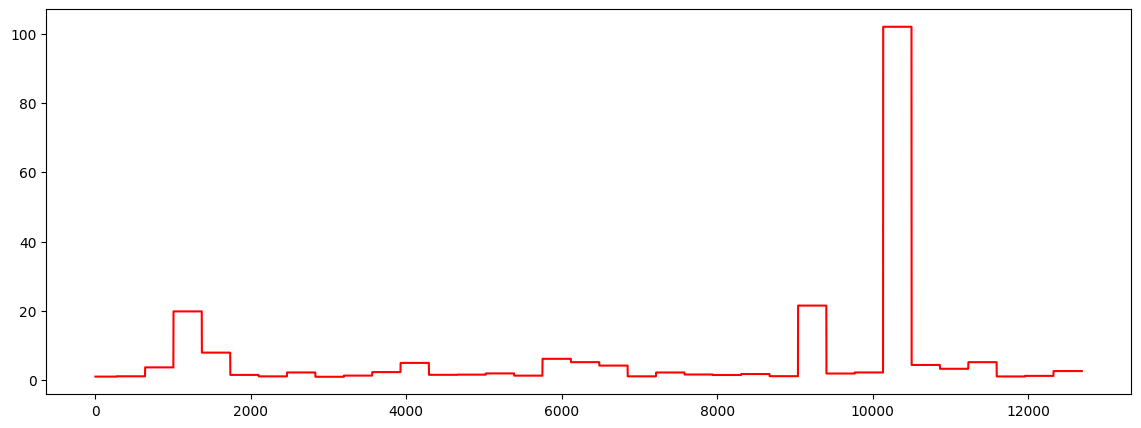

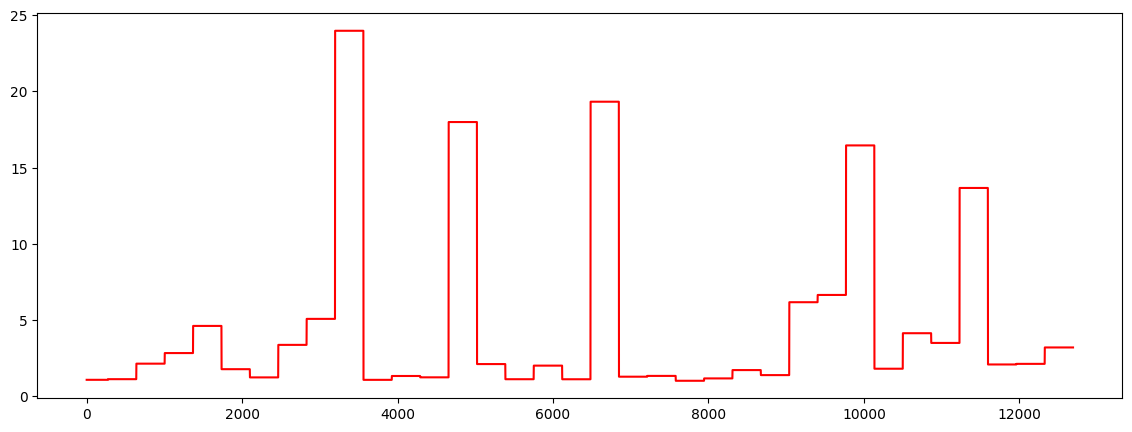

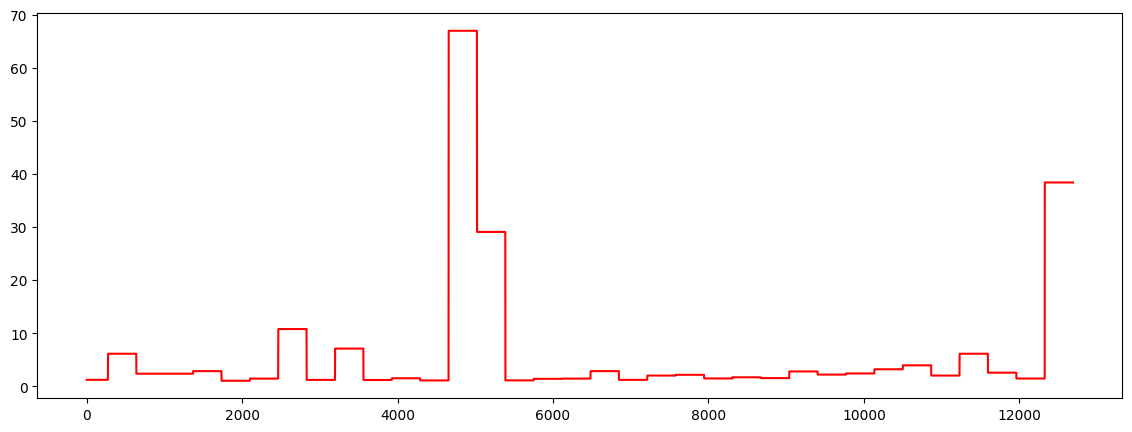

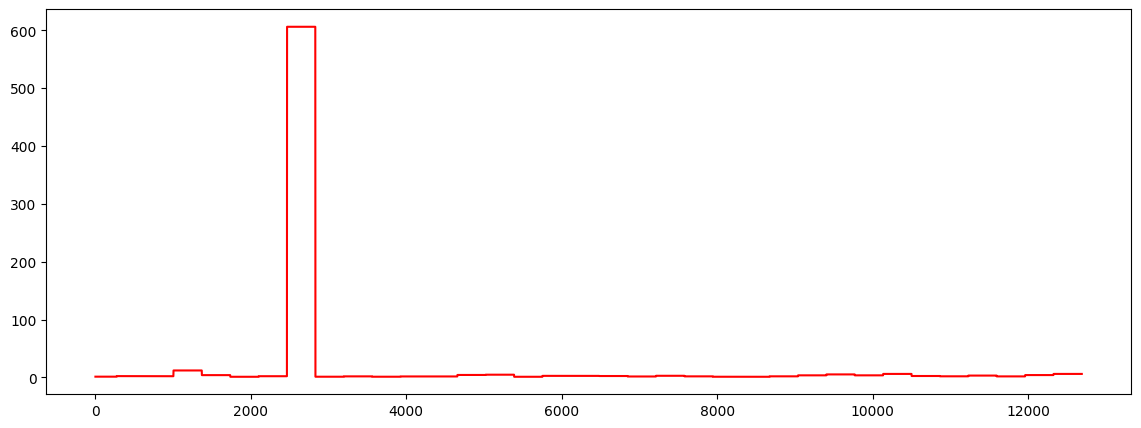

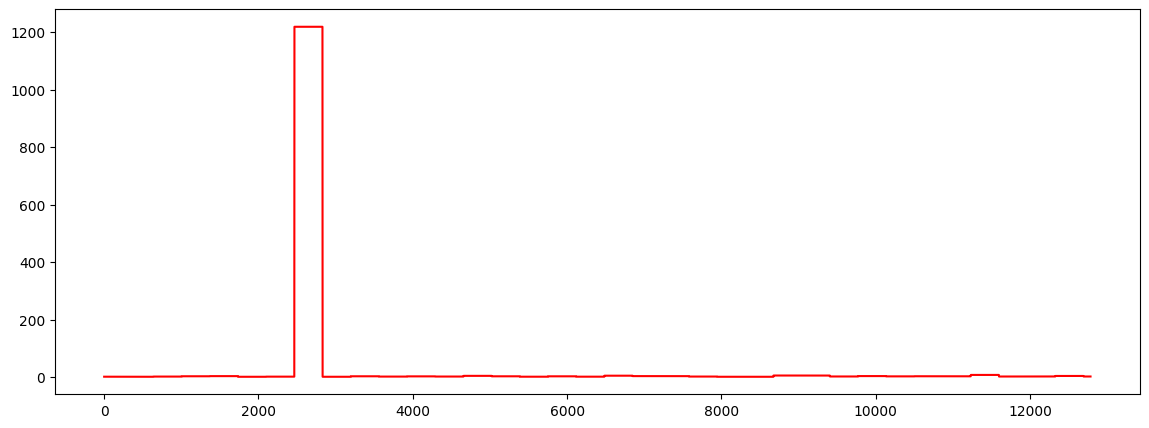

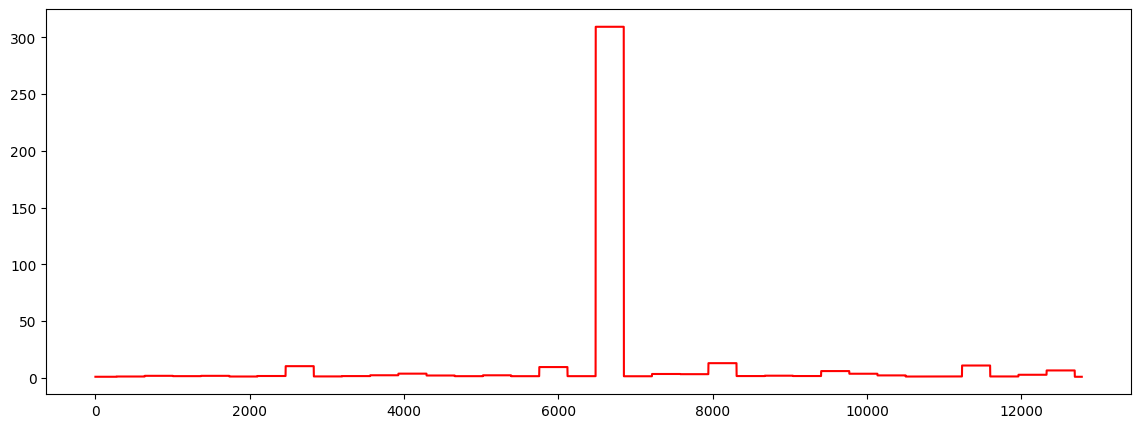

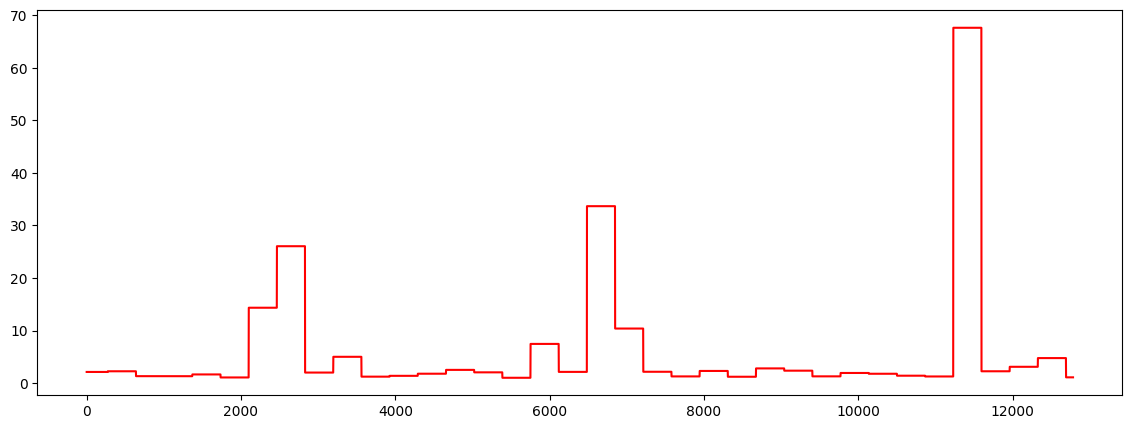

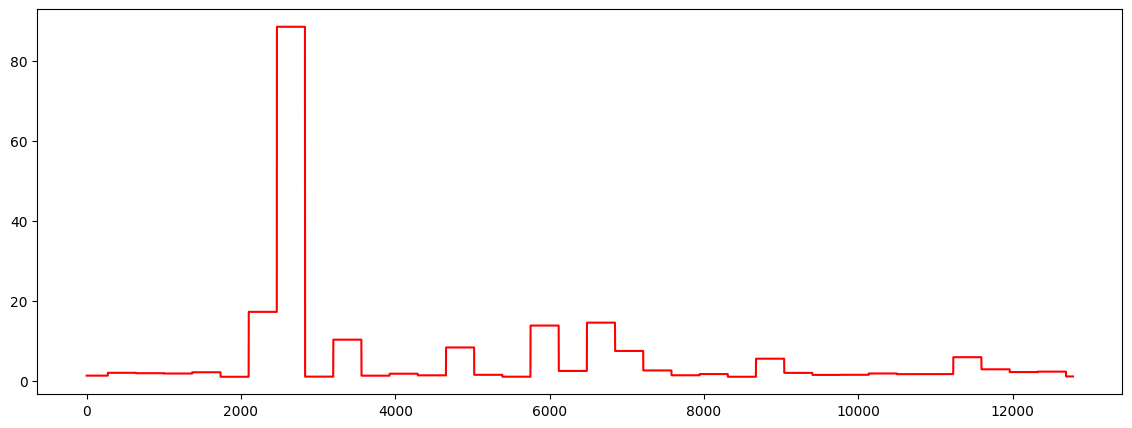

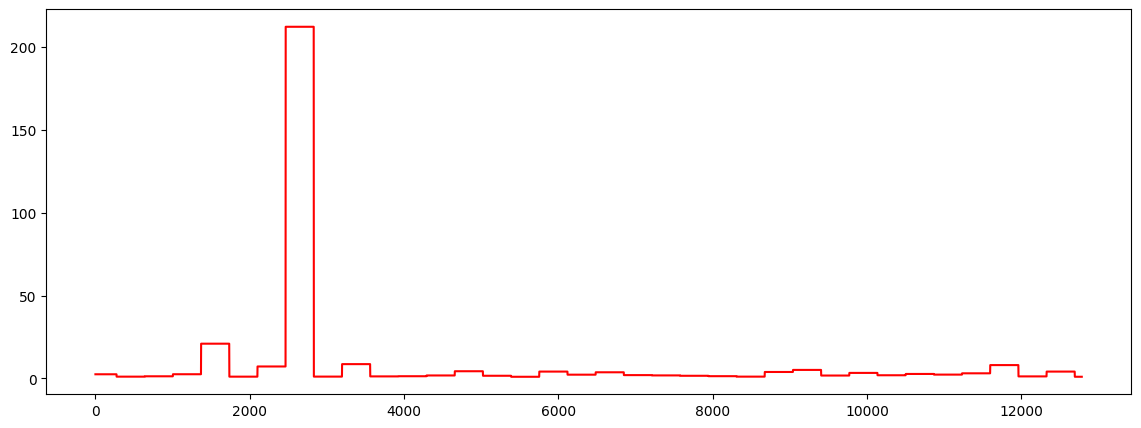

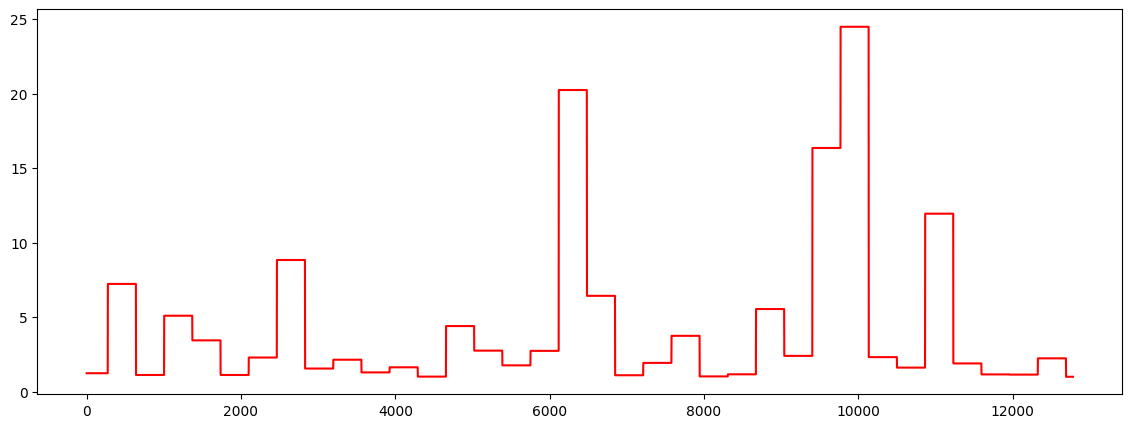

In [11]:
import matplotlib.pyplot as plt
for i in range(10):
    plt.figure(figsize=(14,5))
    plt.plot(return_period[i,:],label='Years', color='red')
    plt.show()


In [1]:
import numpy as np
import pandas as pd
import os

method = "Furey"
model = "HBV"

if model == "HBV":
    dyn = "parBETA_parBETAET_"

elif model == "HBV_capillary":
    dyn = "parBETA_parBETAET_parK0_parUZL_"

elif model == "marrmot_PRMS":
    dyn = "alpha_cgw_scx_tt_"


# ==========================================================
# METRICS
# ==========================================================

def calc_nse(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)

    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    if np.std(obs) == 0 or np.mean(obs) == 0:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    alpha = np.std(sim) / np.std(obs)

    beta = np.mean(sim) / np.mean(obs)

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if np.sum(obs) == 0:
        return np.nan

    return (np.sum(sim) - np.sum(obs)) / np.sum(obs)


def calc_abs_bias(obs, sim):

    mask = np.isfinite(obs) & np.isfinite(sim)

    obs = obs[mask]
    sim = sim[mask]

    if np.sum(obs) == 0:
        return np.nan

    return np.abs(
        (np.sum(sim) - np.sum(obs))
        /
        np.sum(obs)
    )


# ==========================================================
# RETURN PERIODS
# ==========================================================

thresholds = [5, 10, 25, 50, 100]

results_full = {}
results_train = {}
results_test = {}

# ==========================================================
# LOAD THRESHOLD TABLE (mm/day)
# ==========================================================

threshold_df = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/CAMELS_LP3_flood_thresholds_mmday.csv"
)

threshold_df["Gauge_ID"] = threshold_df["Gauge_ID"].astype(int)
threshold_df = threshold_df.set_index("Gauge_ID")

# ==========================================================
# LOAD GAUGE IDS
# ==========================================================

forcing = np.load(
    "/scratch/data/CAMELS_FORCING/daymet_19800101_20141231_forcing_671.npy",
    allow_pickle=True
)

gauge_ids = forcing[:, 0, 14].astype(int)

# ==========================================================
# FUNCTION TO CALCULATE METRICS
# ==========================================================

def metric_table(obs_all, single_all, multi_all, events):

    if len(obs_all) == 0:
        return {
            "Events": 0,
            "Single NSE": np.nan,
            "Multi NSE": np.nan,
            "Single KGE": np.nan,
            "Multi KGE": np.nan,
            "Single Bias": np.nan,
            "Multi Bias": np.nan,
            "Single Abs Bias": np.nan,
            "Multi Abs Bias": np.nan,
            "Samples": 0,
        }

    obs_all = np.concatenate(obs_all)
    single_all = np.concatenate(single_all)
    multi_all = np.concatenate(multi_all)

    return {

        "Days": events,

        "Single NSE":
            calc_nse(obs_all, single_all),

        "Multi NSE":
            calc_nse(obs_all, multi_all),

        "Single KGE":
            calc_kge(obs_all, single_all),

        "Multi KGE":
            calc_kge(obs_all, multi_all),

        "Single Bias":
            calc_bias(obs_all, single_all),

        "Multi Bias":
            calc_bias(obs_all, multi_all),

        "Single Abs Bias":
            calc_abs_bias(obs_all, single_all),

        "Multi Abs Bias":
            calc_abs_bias(obs_all, multi_all),

        "Samples":
            len(obs_all)
    }


# ==========================================================
# LOOP OVER RETURN PERIODS
# ==========================================================

for threshold in thresholds:

    print(f"\nProcessing >{threshold}-year floods")

    obs_full_all = []
    single_full_all = []
    multi_full_all = []

    obs_train_all = []
    single_train_all = []
    multi_train_all = []

    obs_test_all = []
    single_test_all = []
    multi_test_all = []

    full_events = 0
    train_events = 0
    test_events = 0

    # ======================================================
    # LOOP REGIONS
    # ======================================================

    for region in range(1, 8):

        folder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"{method}_Multi/"
            f"Region_{region}/"
        )

        sfolder = (
            f"/home/s0shar47/scratch/"
            f"OUTPUTS_Paper1/PUR/"
            f"OUTPUTS_PUR_Single/"
            f"Region_{region}/"
        )

        model_folder = (
            f"LSTM_{model}_E50_R365_B100_H256_"
            f"tr1989_1999_n16_111111/"
        )

        obs = np.load(
            os.path.join(
                folder,
                model_folder,
                dyn,
                "ts1980_2014",
                "00060_Mean.npy"
            )
        )

        sim_multi = np.squeeze(
            np.load(
                os.path.join(
                    folder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )

        sim_single = np.squeeze(
            np.load(
                os.path.join(
                    sfolder,
                    model_folder,
                    dyn,
                    "ts1980_2014",
                    "flow_sim.npy"
                )
            )
        )

        dates = pd.date_range(
            "1981-01-01",
            periods=obs.shape[0],
            freq="D"
        )

        train_mask = (
            (dates >= "1989-10-01") &
            (dates <= "1999-09-30")
        )

        test_mask = ~train_mask

        # ==================================================
        # LOOP BASINS
        # ==================================================

        for basin in range(obs.shape[1]):

            gauge_id = gauge_ids[basin]

            if gauge_id not in threshold_df.index:
                continue

            flow_threshold = threshold_df.loc[
                gauge_id,
                f"Q_{threshold}yr"
            ]

            if not np.isfinite(flow_threshold):
                continue

            event_mask = (
                np.isfinite(obs[:, basin]) &
                (obs[:, basin] >= flow_threshold)
            )

            if not np.any(event_mask):
                continue

            # ---------------- FULL ----------------

            obs_full_all.append(
                obs[event_mask, basin]
            )

            single_full_all.append(
                sim_single[event_mask, basin]
            )

            multi_full_all.append(
                sim_multi[event_mask, basin]
            )

            full_events += np.sum(event_mask)

            # ---------------- TRAIN ----------------

            m = event_mask & train_mask

            if np.any(m):

                obs_train_all.append(
                    obs[m, basin]
                )

                single_train_all.append(
                    sim_single[m, basin]
                )

                multi_train_all.append(
                    sim_multi[m, basin]
                )

                train_events += np.sum(m)

            # ---------------- TEST ----------------

            m = event_mask & test_mask

            if np.any(m):

                obs_test_all.append(
                    obs[m, basin]
                )

                single_test_all.append(
                    sim_single[m, basin]
                )

                multi_test_all.append(
                    sim_multi[m, basin]
                )

                test_events += np.sum(m)

    # ======================================================
    # SAVE RESULTS
    # ======================================================

    results_full[threshold] = metric_table(
        obs_full_all,
        single_full_all,
        multi_full_all,
        full_events
    )

    results_train[threshold] = metric_table(
        obs_train_all,
        single_train_all,
        multi_train_all,
        train_events
    )

    results_test[threshold] = metric_table(
        obs_test_all,
        single_test_all,
        multi_test_all,
        test_events
    )


# ==========================================================
# SUMMARY TABLES
# ==========================================================

summary_full = pd.DataFrame(results_full).T
summary_train = pd.DataFrame(results_train).T
summary_test = pd.DataFrame(results_test).T

print(model, method)

print("\n================ FULL PERIOD =================")
display(summary_full)

print("\n================ TRAIN PERIOD =================")
display(summary_train)

print("\n================ EXCLUDING TRAIN PERIOD =================")
display(summary_test)


Processing >5-year floods

Processing >10-year floods

Processing >25-year floods

Processing >50-year floods

Processing >100-year floods
HBV Furey

================ FULL PERIOD =================


,Days,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,27438.0,0.273715,0.265739,0.501961,0.501514,-0.309399,-0.317425,0.309399,0.317425,27438.0
10,17561.0,0.233346,0.227535,0.476404,0.477831,-0.323604,-0.330418,0.323604,0.330418,17561.0
25,11189.0,0.201342,0.198304,0.451360,0.455351,-0.334462,-0.340148,0.334462,0.340148,11189.0
50,8411.0,0.174433,0.174175,0.434423,0.441245,-0.337797,-0.342894,0.337797,0.342894,8411.0
100,6682.0,0.155940,0.159037,0.425369,0.435281,-0.336398,-0.340581,0.336398,0.340581,6682.0



================ TRAIN PERIOD =================


,Days,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,9355.0,0.313938,0.308061,0.526238,0.526761,-0.298757,-0.305694,0.298757,0.305694,9355.0
10,6124.0,0.275721,0.273719,0.504901,0.507756,-0.312036,-0.316972,0.312036,0.316972,6124.0
25,3961.0,0.255028,0.254434,0.484751,0.489914,-0.320621,-0.325587,0.320621,0.325587,3961.0
50,2998.0,0.236904,0.239061,0.473120,0.480674,-0.321712,-0.327024,0.321712,0.327024,2998.0
100,2385.0,0.225709,0.231186,0.464538,0.475863,-0.320385,-0.324695,0.320385,0.324695,2385.0



================ EXCLUDING TRAIN PERIOD =================


,Days,Single NSE,Multi NSE,Single KGE,Multi KGE,Single Bias,Multi Bias,Single Abs Bias,Multi Abs Bias,Samples
5,18083.0,0.246594,0.237342,0.486211,0.485219,-0.315344,-0.323977,0.315344,0.323977,18083.0
10,11437.0,0.204393,0.196288,0.457592,0.458142,-0.330288,-0.338187,0.330288,0.338187,11437.0
25,7228.0,0.165012,0.160483,0.428832,0.432140,-0.342632,-0.348743,0.342632,0.348743,7228.0
50,5413.0,0.133023,0.131311,0.408279,0.414743,-0.347364,-0.352332,0.347364,0.352332,5413.0
100,4297.0,0.109800,0.111460,0.398637,0.407755,-0.345899,-0.350007,0.345899,0.350007,4297.0


In [3]:
## Select the number of objectives
# objective= 'Multi'
objectives= ['Single', 'Multi']

method= 'Furey'
methods= ['USGS', 'Furey']
## Select the test
test= 'PUR'
tests= ['PUB','PUR']

## Select the model
model= 'HBV'
models= ['HBV', 'PRMS', 'HBV_capillary']

if model=='HBV':
    dyn= 'parBETA_parBETAET_'

if model=='marrmot_PRMS':
    dyn= 'alpha_cgw_scx_tt_'

if model=='HBV_capillary':
    dyn= 'parBETA_parBETAET_parK0_parUZL_'

if test== 'PUB':
    n=11
if test== 'PUR':
    n=8

    
import numpy as np
import os

def calc_nse(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    den = np.sum((obs - np.mean(obs)) ** 2)
    if den == 0:
        return np.nan

    return 1 - np.sum((obs - sim) ** 2) / den


def calc_kge(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    if len(obs) < 2:
        return np.nan

    r = np.corrcoef(obs, sim)[0, 1]

    std_obs = np.std(obs)
    std_sim = np.std(sim)

    if std_obs == 0:
        return np.nan

    alpha = std_sim / std_obs

    mean_obs = np.mean(obs)
    if mean_obs == 0:
        return np.nan

    beta = np.mean(sim) / mean_obs

    return 1 - np.sqrt(
        (r - 1) ** 2 +
        (alpha - 1) ** 2 +
        (beta - 1) ** 2
    )


def calc_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return (np.sum(sim) - den) / den


def calc_abs_bias(obs, sim):
    mask = np.isfinite(obs) & np.isfinite(sim)
    obs = obs[mask]
    sim = sim[mask]

    den = np.sum(obs)
    if den == 0:
        return np.nan

    return np.abs(np.sum(sim) - den) / den


models= ['HBV', 'HBV_capillary', 'marrmot_PRMS']

for k in range(len(models)):
    model= models[k]

    if model=='HBV':
        dyn= 'parBETA_parBETAET_'

    if model=='marrmot_PRMS':
        dyn= 'alpha_cgw_scx_tt_'

    if model=='HBV_capillary':
        dyn= 'parBETA_parBETAET_parK0_parUZL_'

# ============================================================
# Metric functions
# ============================================================



# ============================================================
# Containers
# ============================================================

    metrics_old = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    metrics_new = {
        "NSE": [],
        "KGE": [],
        "Bias": [],
        "AbsBias": [],
        "NSE_low": [],
        "NSE_high": [],
        "Bias_low": [],
        "Bias_high": [],
        "AbsBias_low": [],
        "AbsBias_high": [],
    }

    # ============================================================
    # Loop over folds
    # ============================================================

    for i in range(1, n):


        if test== 'PUB':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_PUB_{objectives[1]}/{model}/{i}/"
            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/{test}/OUTPUTS_PUB_{objectives[0]}/{model}/{i}/"
            gauge = np.load(
                f"/home/s0shar47/scratch/BASEFLOW_FOLDS/{i}/test/DAYMET_19800101_20141231_forcing_baseflow_mmday.npy")
 

        if test== 'PUR':
            folder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/{method}_{objectives[1]}/Region_{i}/"

            sfolder= f"/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_{objectives[0]}/Region_{i}/"


        obs_flow = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/00060_Mean.npy")
        )

        sim_old = np.load(
            os.path.join(sfolder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Single/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"

        )

        sim_new = np.load(
            os.path.join(folder,f"LSTM_{model}_E50_R365_B100_H256_tr1989_1999_n16_111111/{dyn}/ts1989_1999/flow_sim.npy")
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1989_1999/flow_sim.npy"
            # f"/home/s0shar47/scratch/OUTPUTS_PUR_Multi/Region_{i}/LSTM_HBV_capillary_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_parK0_parUZL_/ts1989_1999/flow_sim.npy"
        )

        sim_old = np.squeeze(sim_old)
        sim_new = np.squeeze(sim_new)

        # --------------------------------------------------------
        # Loop over basins
        # --------------------------------------------------------
        for k in range(obs_flow.shape[1]):

            obs = obs_flow[:, k]
            old = sim_old[:, k]
            new = sim_new[:, k]

            # =====================================================
            # Overall metrics
            # =====================================================
            metrics_old["NSE"].append(calc_nse(obs, old))
            metrics_new["NSE"].append(calc_nse(obs, new))

            metrics_old["KGE"].append(calc_kge(obs, old))
            metrics_new["KGE"].append(calc_kge(obs, new))

            metrics_old["Bias"].append(calc_bias(obs, old))
            metrics_new["Bias"].append(calc_bias(obs, new))

            metrics_old["AbsBias"].append(calc_abs_bias(obs, old))
            metrics_new["AbsBias"].append(calc_abs_bias(obs, new))

            # =====================================================
            # Low / High flow
            # =====================================================
            threshold = np.median(obs)
            # print(threshold, np.mean(obs))

            low = obs <= threshold
            high = obs > threshold


            # print(f"Num_overall:{np.sum((obs - new) ** 2)}")
            # print(f"Den_overall:{np.sum((obs - np.mean(obs)) ** 2)}")
            # print(f"Overall Mean:{np.mean(obs)}")

            # print(f"Num_high:{np.sum((obs[high]- new[high])** 2)}")
            # print(f":Den_high:{np.sum((obs[high] - np.mean(obs[high])) ** 2)}")
            # print(f"High Mean:{np.mean(obs[high])}")


            # print(f"Num_low:{np.sum((obs[low] - new[low]) ** 2)}")
            # print(f"Den_low:{np.sum((obs[low] - np.mean(obs[low])) ** 2)}")
            # print(f"Low Mean:{np.mean(obs[low])}")


            # ---------------- Low flow ----------------
            if np.sum(low) > 2:

                metrics_old["NSE_low"].append(calc_nse(obs[low], old[low]))
                metrics_new["NSE_low"].append(calc_nse(obs[low], new[low]))

                metrics_old["Bias_low"].append(calc_bias(obs[low], old[low]))
                metrics_new["Bias_low"].append(calc_bias(obs[low], new[low]))

                metrics_old["AbsBias_low"].append(
                    calc_abs_bias(obs[low], old[low])
                )
                metrics_new["AbsBias_low"].append(
                    calc_abs_bias(obs[low], new[low])
                )

            # ---------------- High flow ----------------
            if np.sum(high) > 2:

                metrics_old["NSE_high"].append(calc_nse(obs[high], old[high]))
                metrics_new["NSE_high"].append(calc_nse(obs[high], new[high]))

                metrics_old["Bias_high"].append(calc_bias(obs[high], old[high]))
                metrics_new["Bias_high"].append(calc_bias(obs[high], new[high]))

                metrics_old["AbsBias_high"].append(
                    calc_abs_bias(obs[high], old[high])
                )
                metrics_new["AbsBias_high"].append(
                    calc_abs_bias(obs[high], new[high])
                )

    # ============================================================
    # Print comparison
    # ============================================================

    # print("\n" + "=" * 60)
    print(f"{test} Test FLOW COMPARISON ({model} 1989-1999) using {method} for baseflow separation with median as threshold")
    # print("=" * 60)

    metric_order = [
        "NSE",
        "KGE",
        "Bias",
        "AbsBias",
        "NSE_low",
        "NSE_high",
        "Bias_low",
        "Bias_high",
        "AbsBias_low",
        "AbsBias_high",
    ]

    for metric in metric_order:
        old = np.nanmedian(metrics_old[metric])
        new = np.nanmedian(metrics_new[metric])
        print(f"{metric:<13}: {old:8.4f} → {new:8.4f}")

    print("=" * 60)

PUR Test FLOW COMPARISON (HBV 1989-1999) using Furey for baseflow separation with median as threshold
NSE          :   0.6331 →   0.6345
KGE          :   0.6501 →   0.6574
Bias         :  -0.0340 →  -0.0538
AbsBias      :   0.1284 →   0.1231
NSE_low      :  -3.7524 →  -3.9197
NSE_high     :   0.5765 →   0.5652
Bias_low     :   0.3044 →   0.2529
Bias_high    :  -0.0698 →  -0.0770
AbsBias_low  :   0.4468 →   0.4502
AbsBias_high :   0.1431 →   0.1369
PUR Test FLOW COMPARISON (HBV_capillary 1989-1999) using Furey for baseflow separation with median as threshold
NSE          :   0.6214 →   0.6358
KGE          :   0.6281 →   0.6553
Bias         :  -0.0372 →  -0.0575
AbsBias      :   0.1302 →   0.1310
NSE_low      :  -4.1002 →  -3.1722
NSE_high     :   0.5530 →   0.5733
Bias_low     :   0.3863 →   0.2533
Bias_high    :  -0.0687 →  -0.0888
AbsBias_low  :   0.4840 →   0.4376
AbsBias_high :   0.1408 →   0.1449
PUR Test FLOW COMPARISON (marrmot_PRMS 1989-1999) using Furey for baseflow separation 

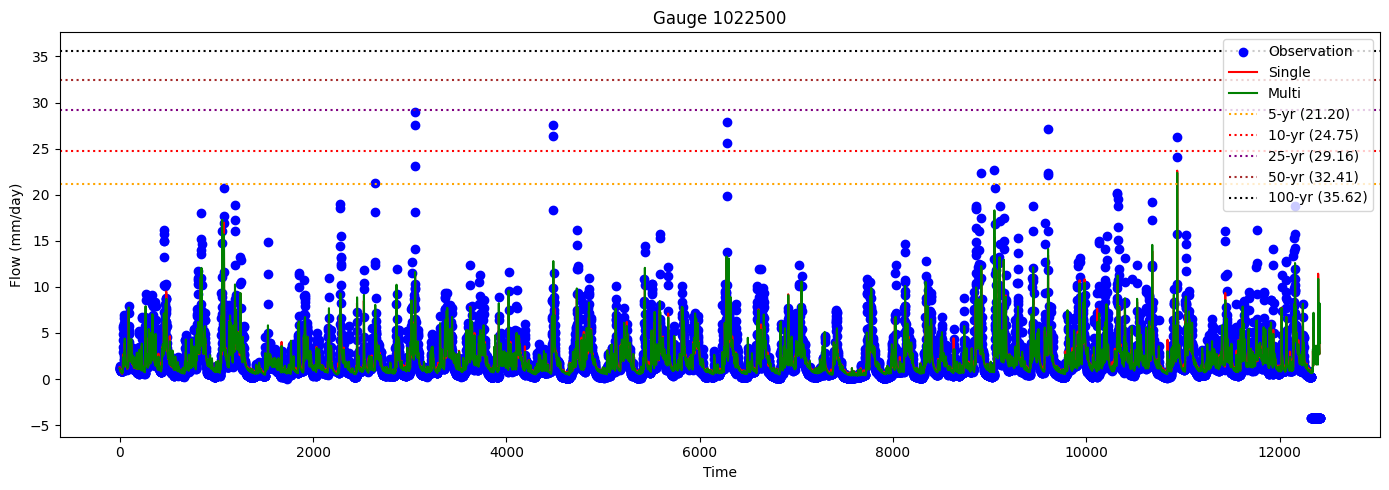

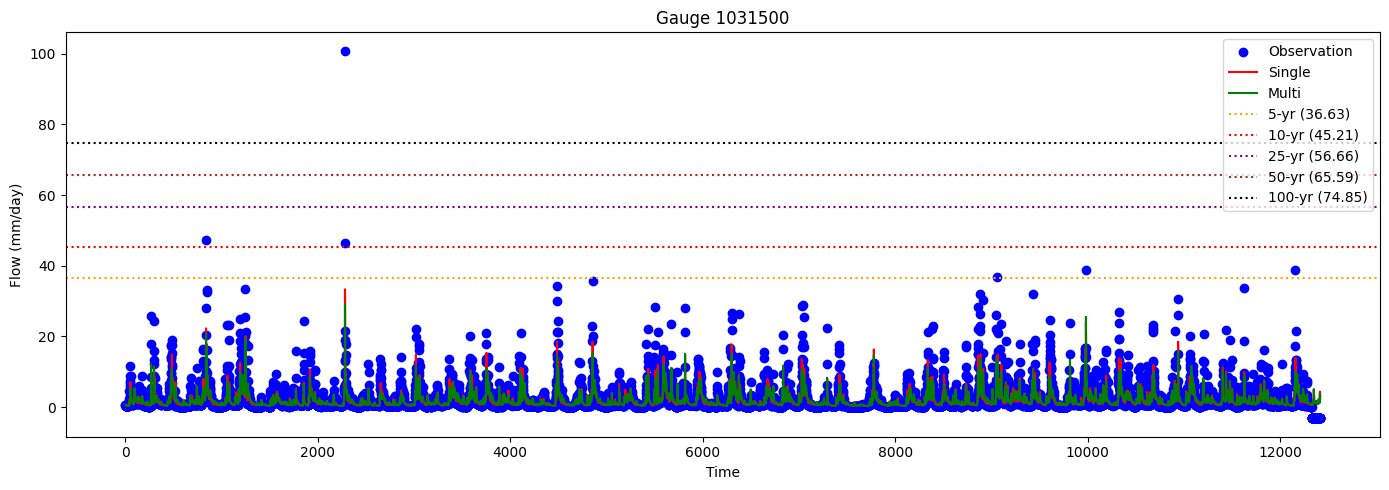

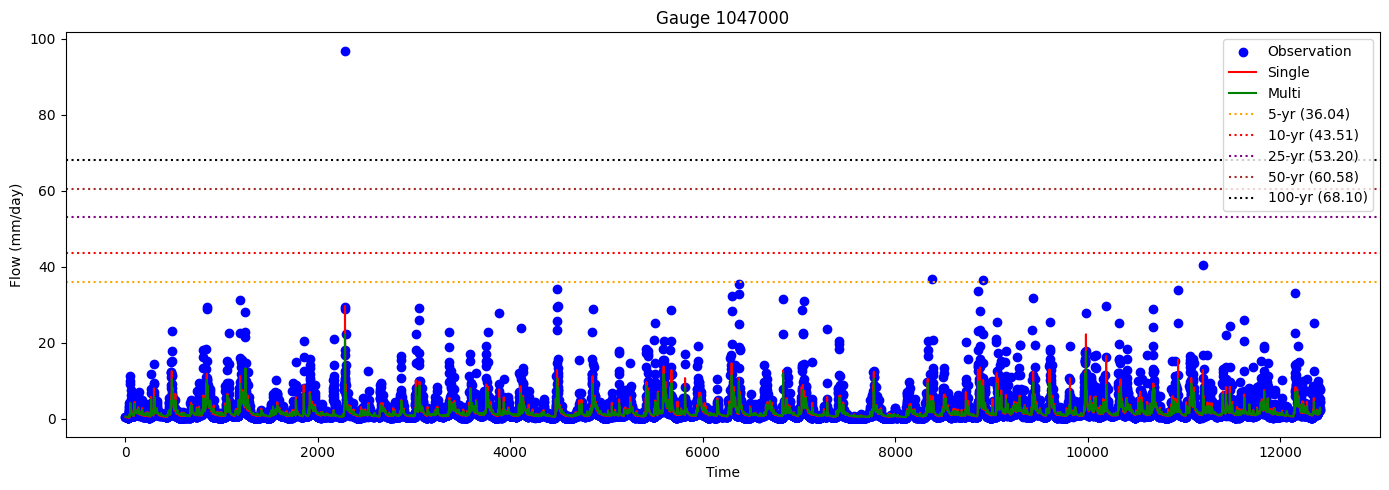

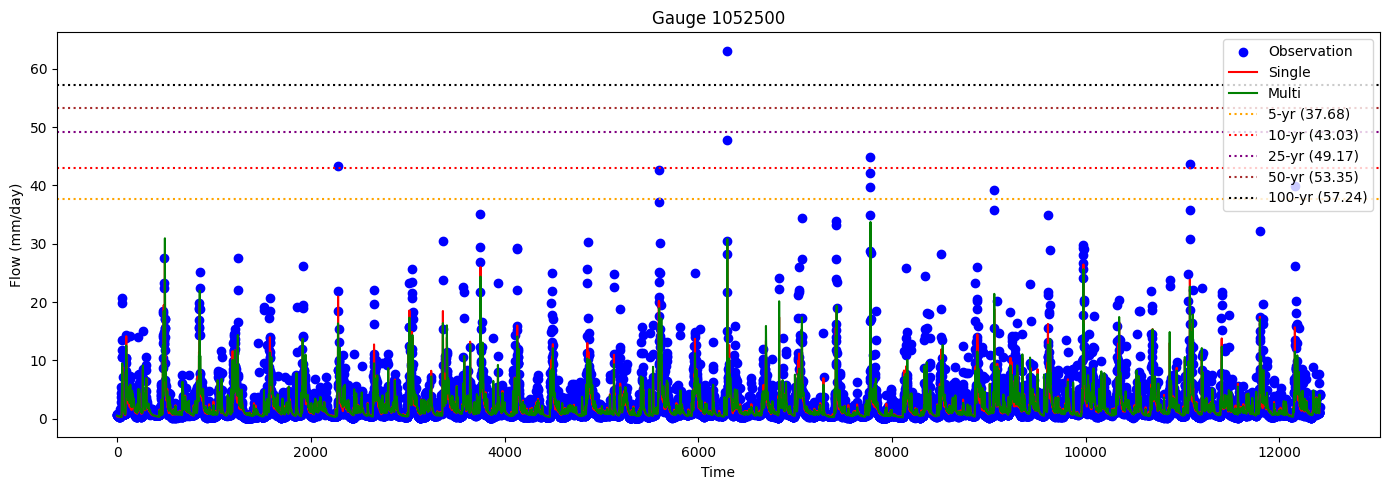

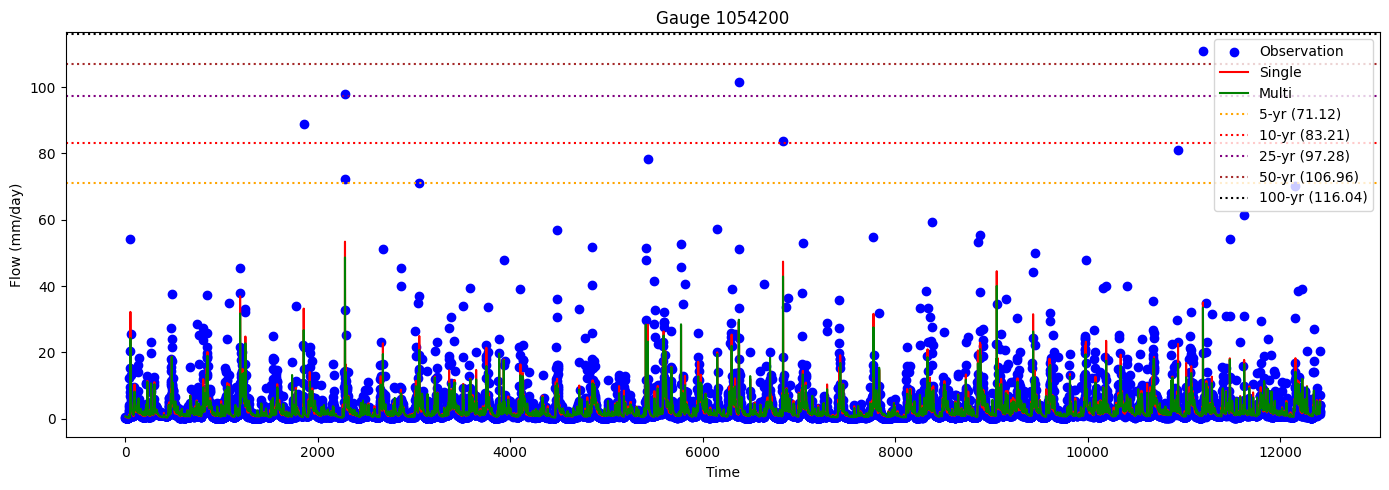

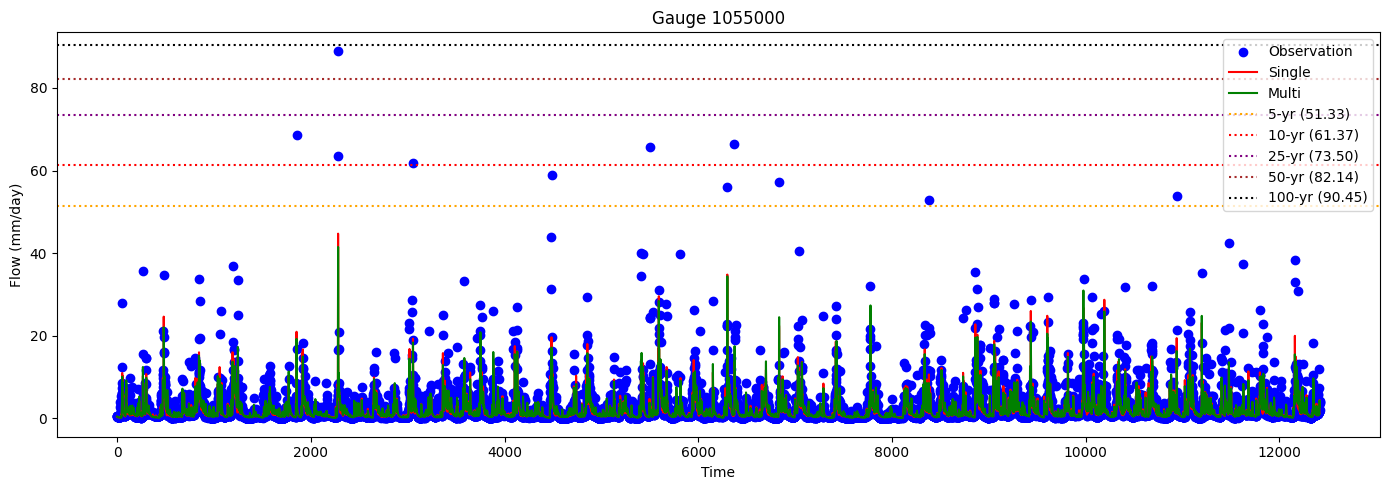

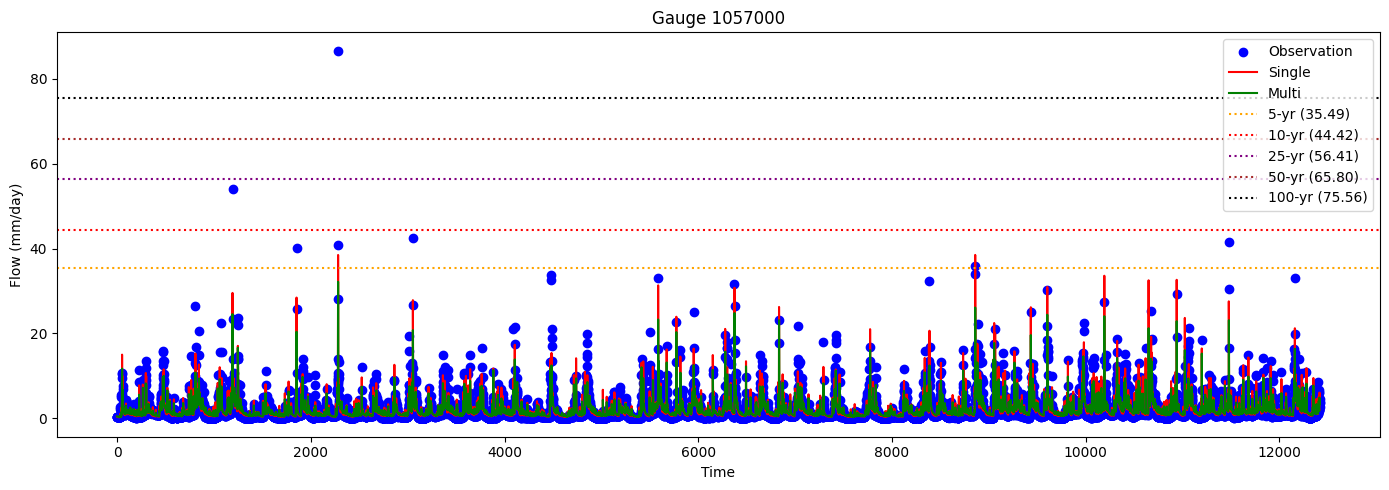

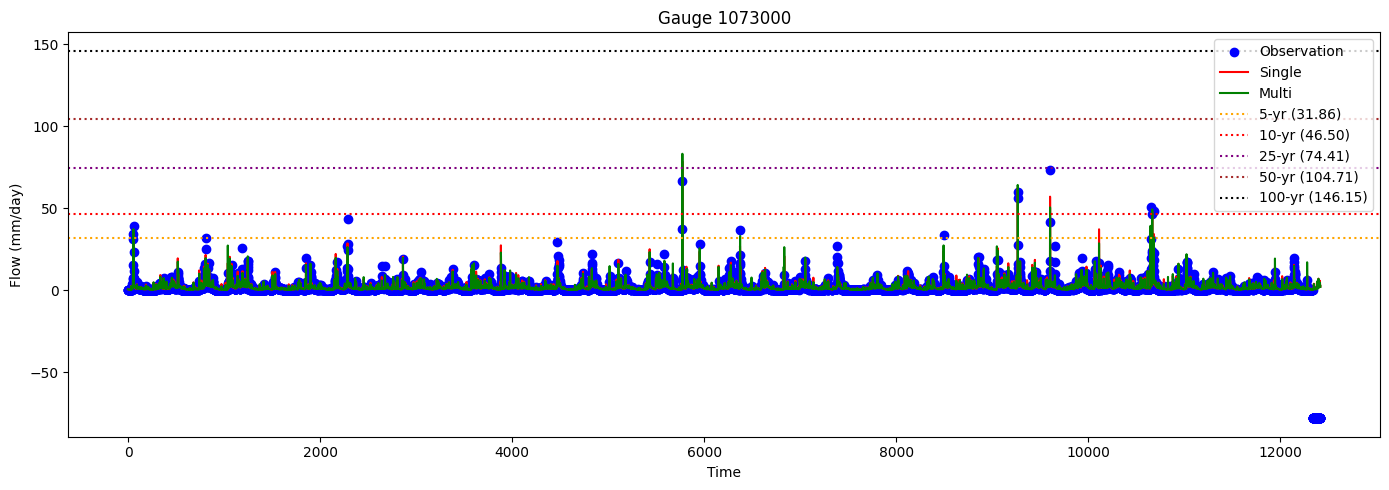

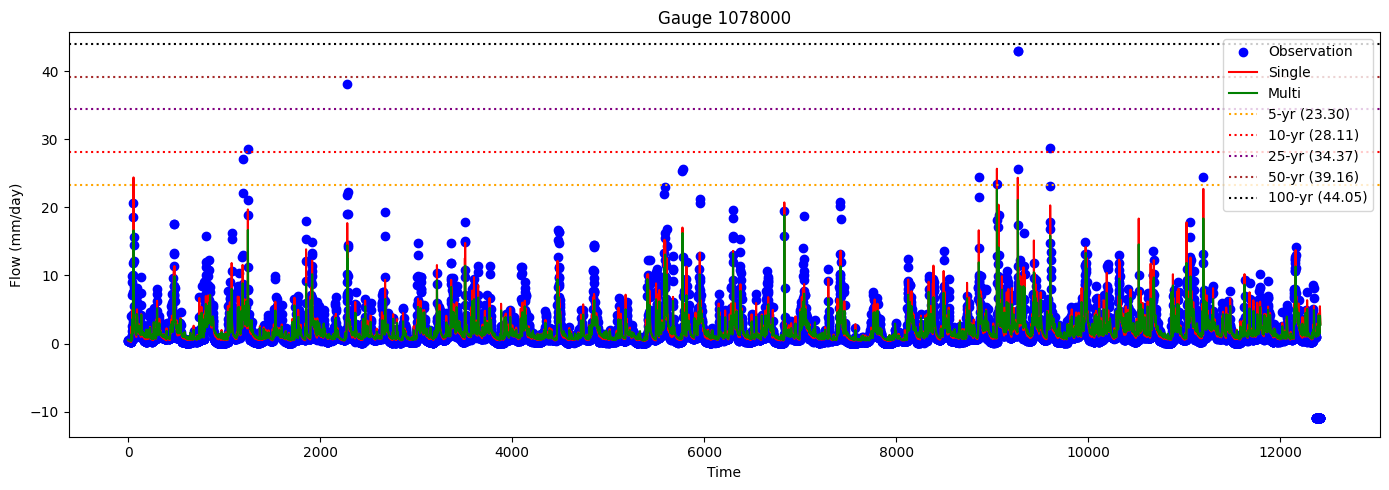

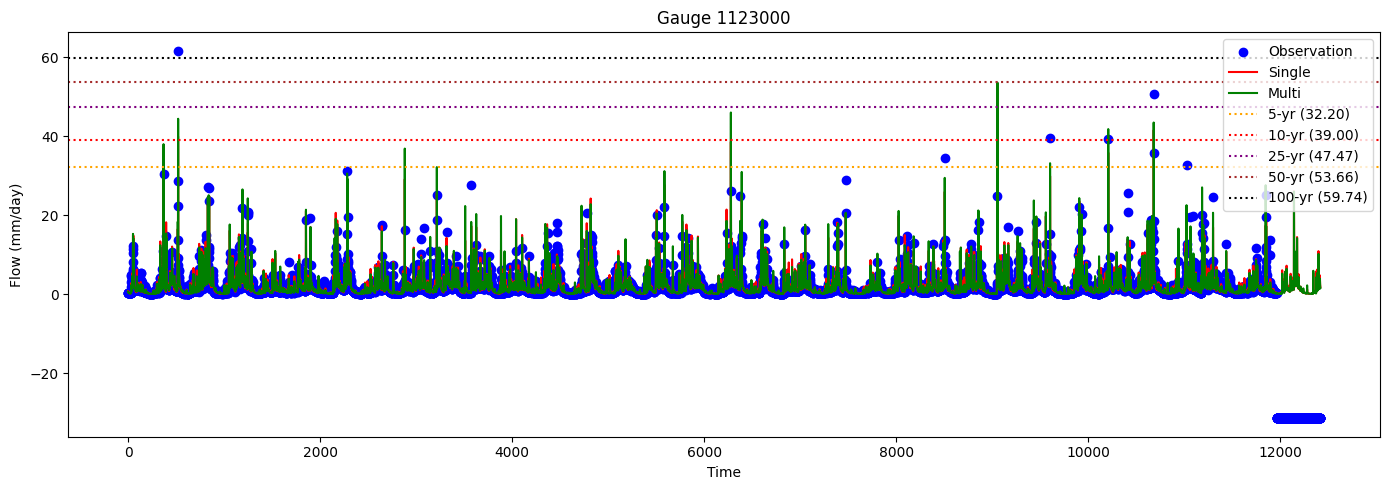

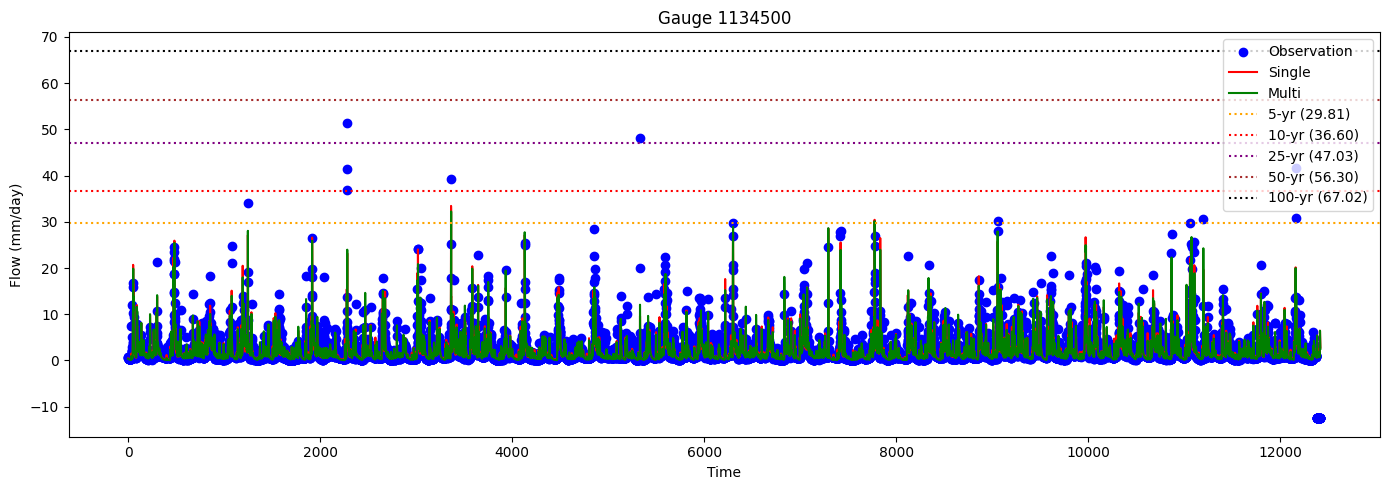

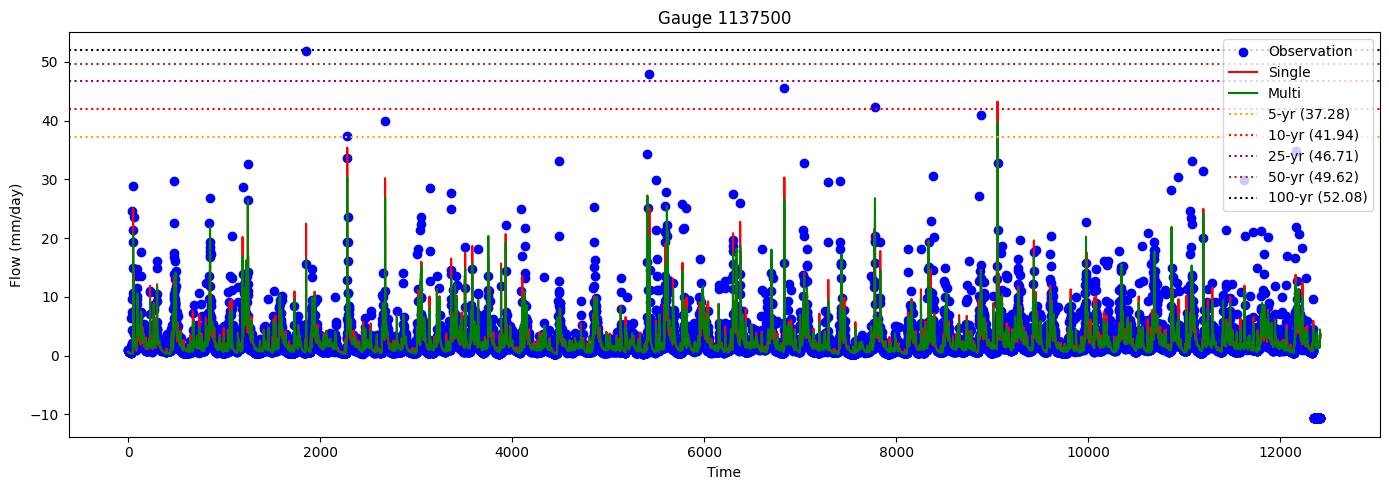

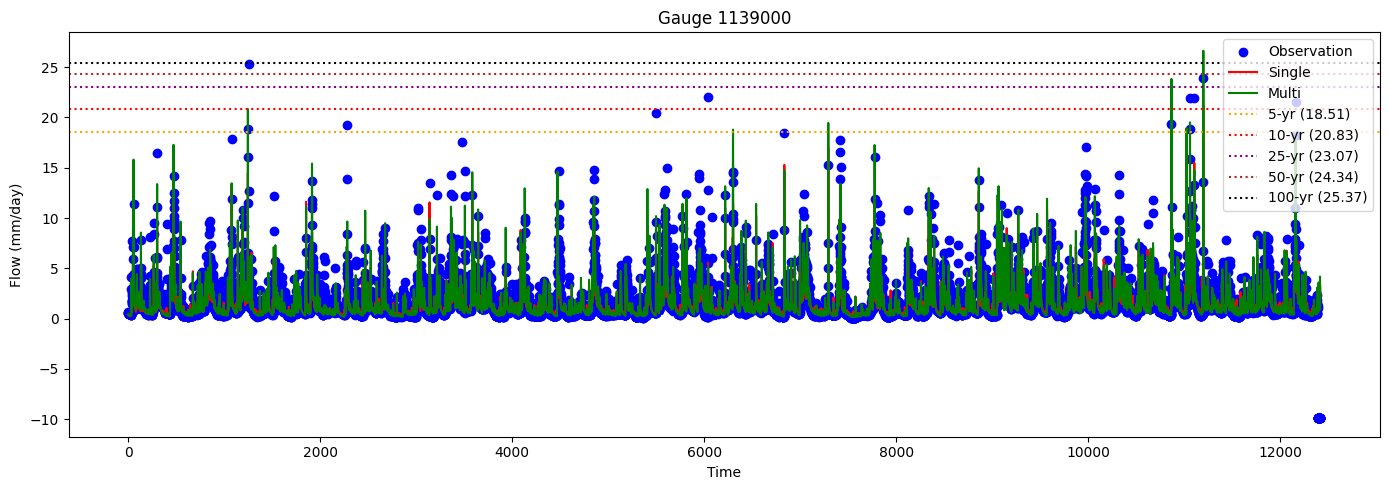

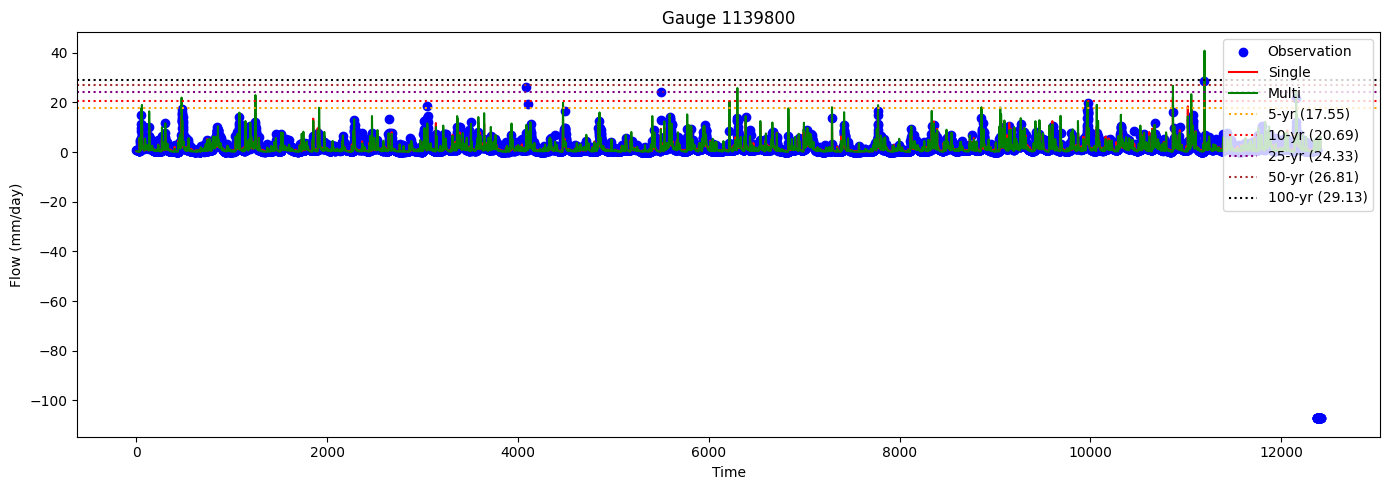

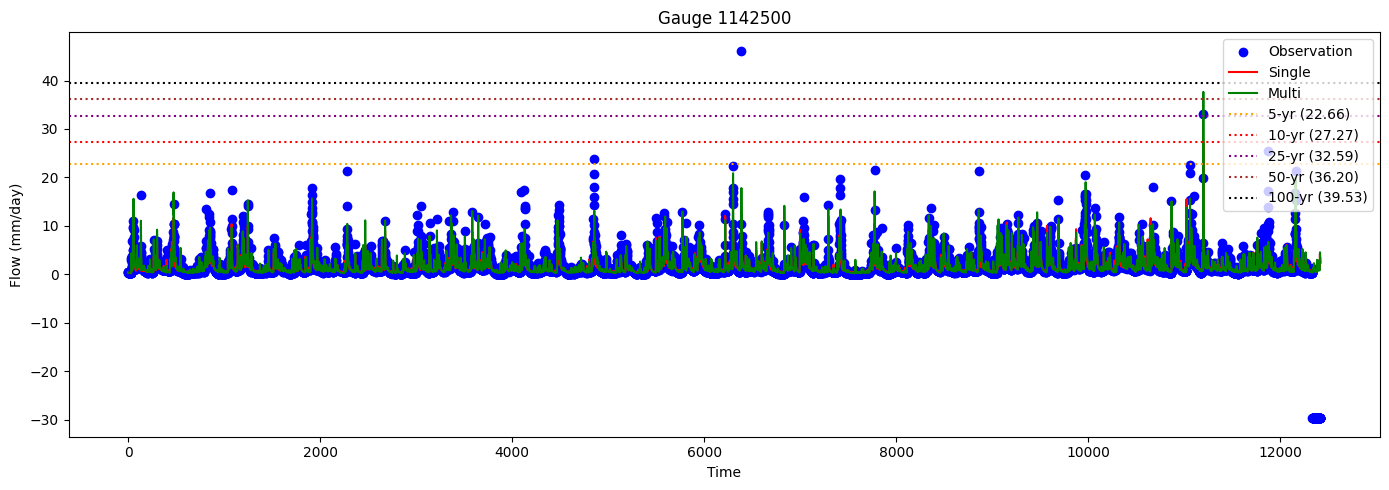

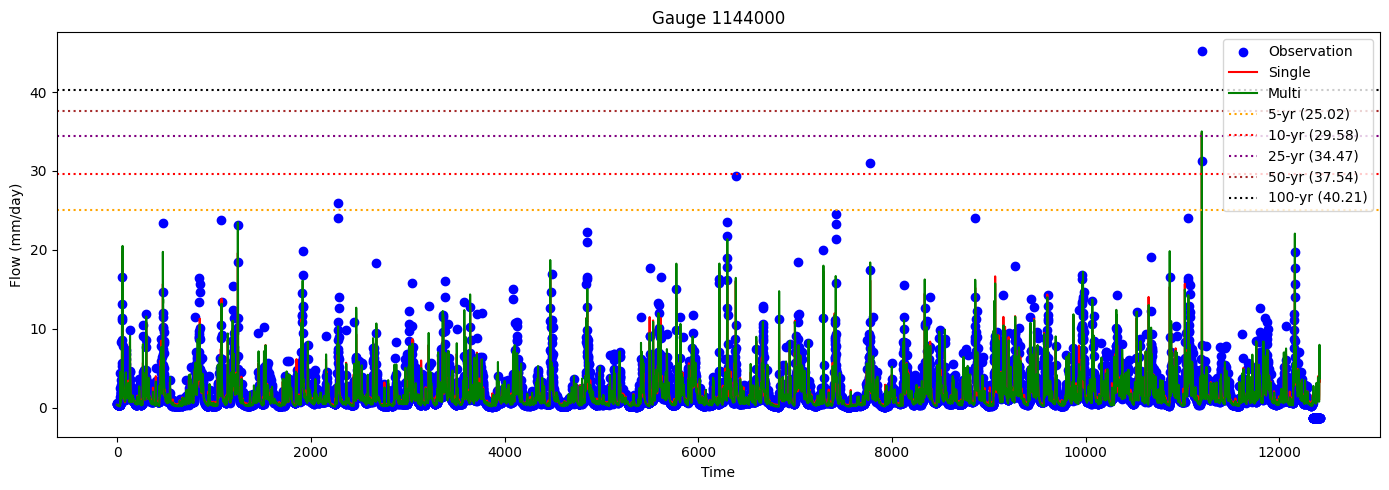

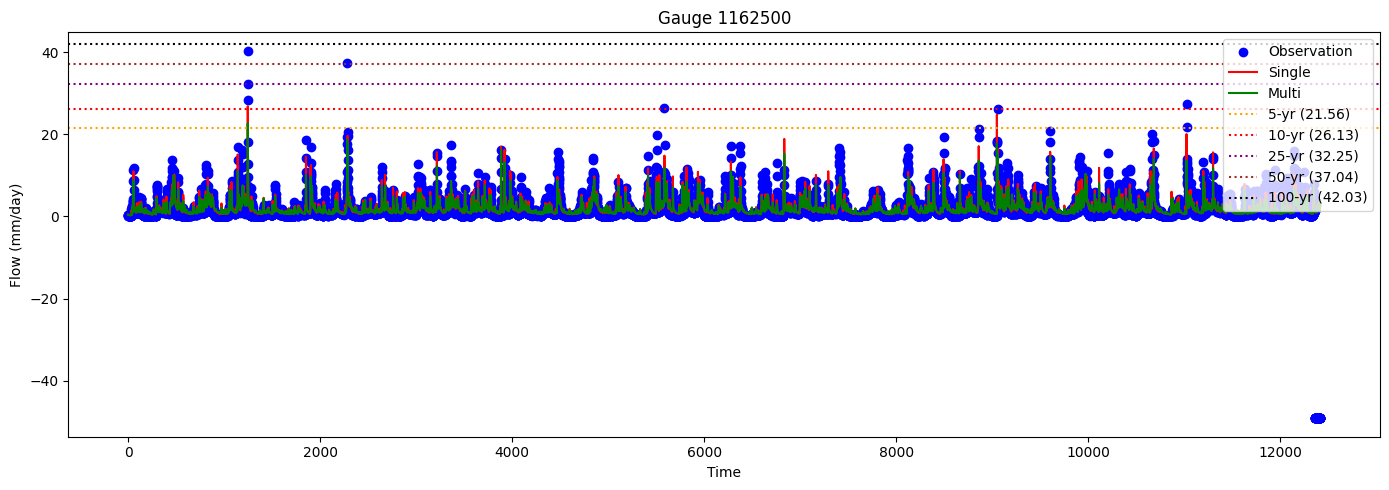

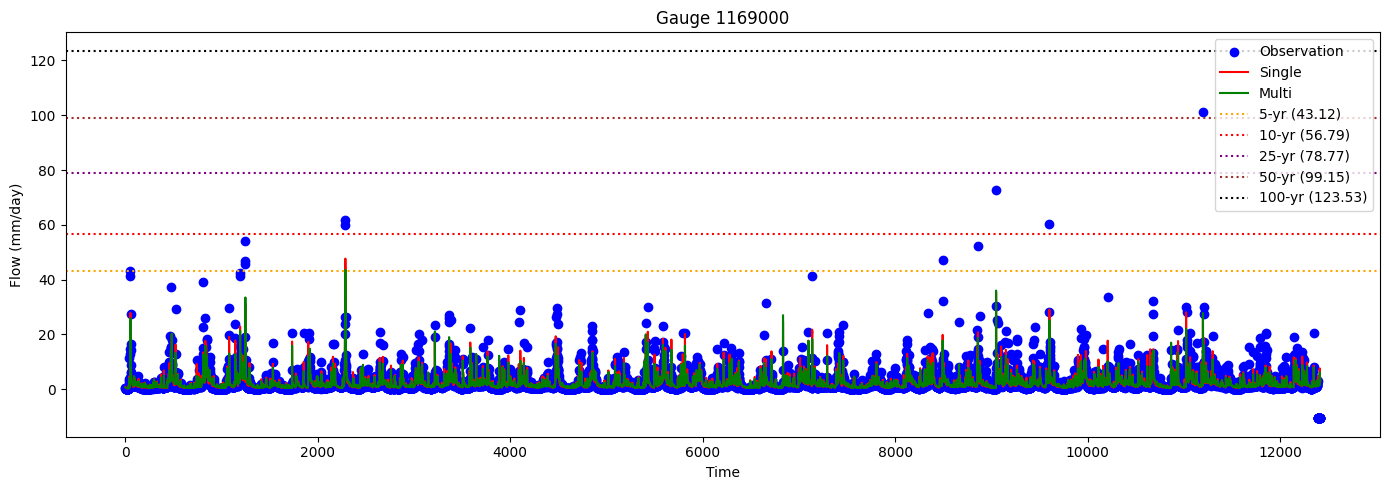

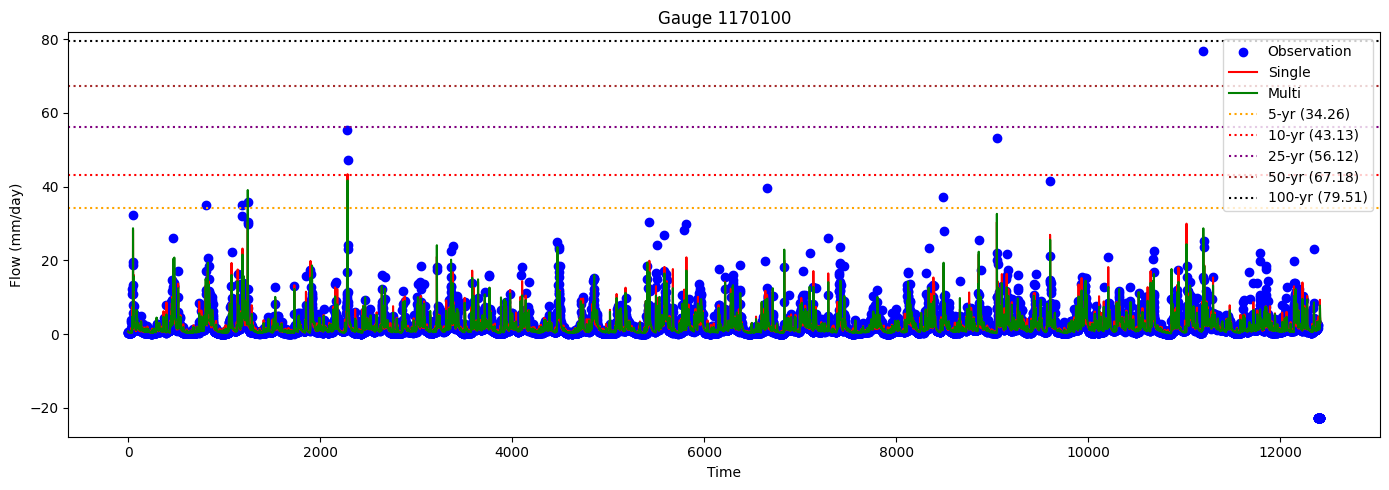

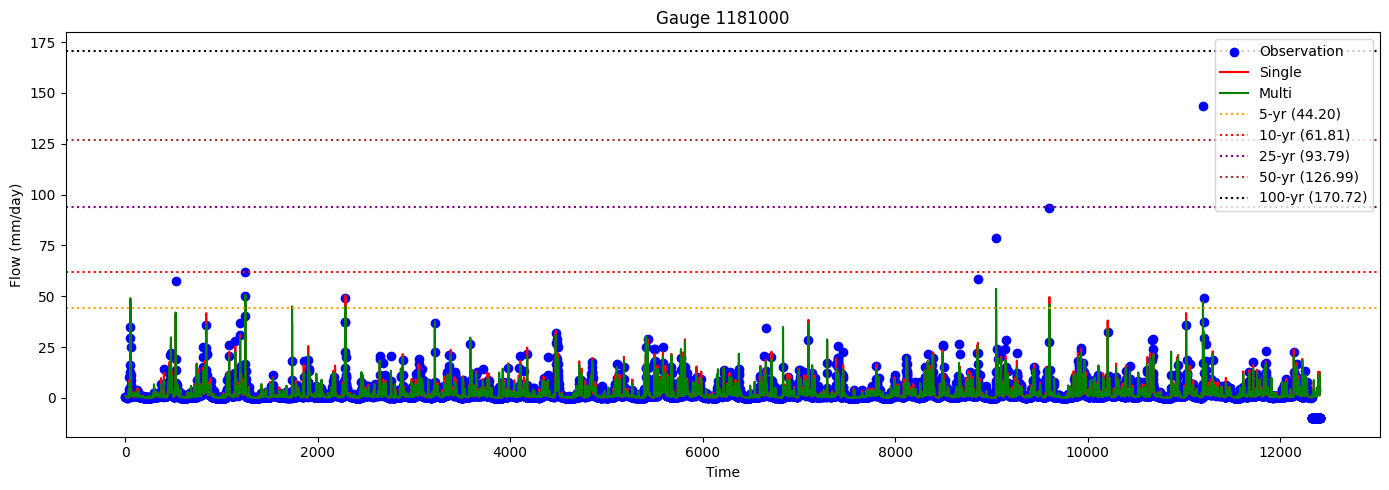

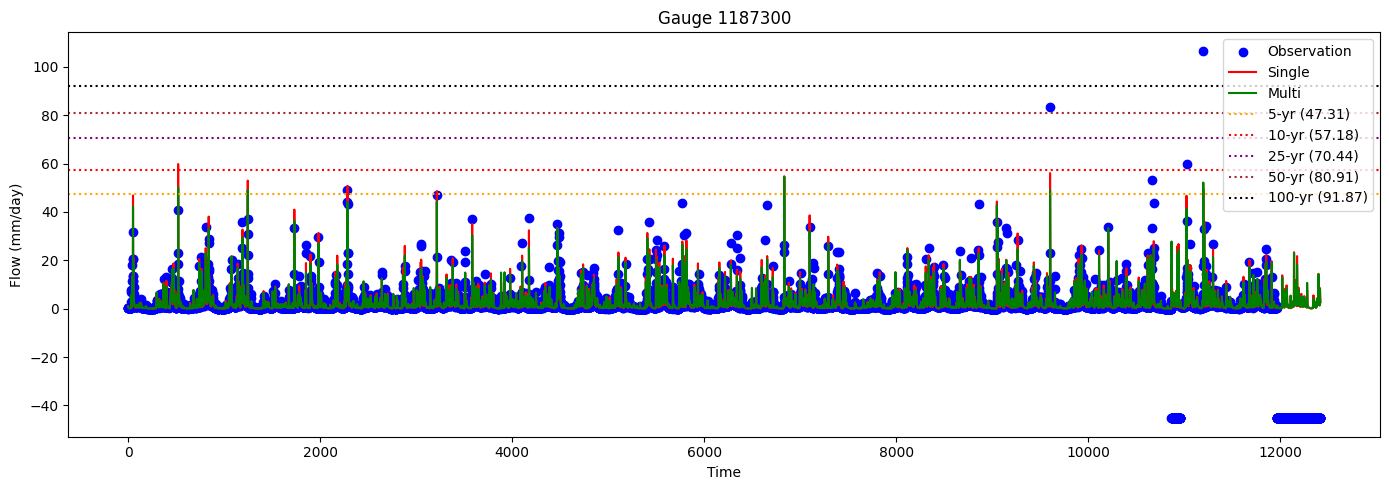

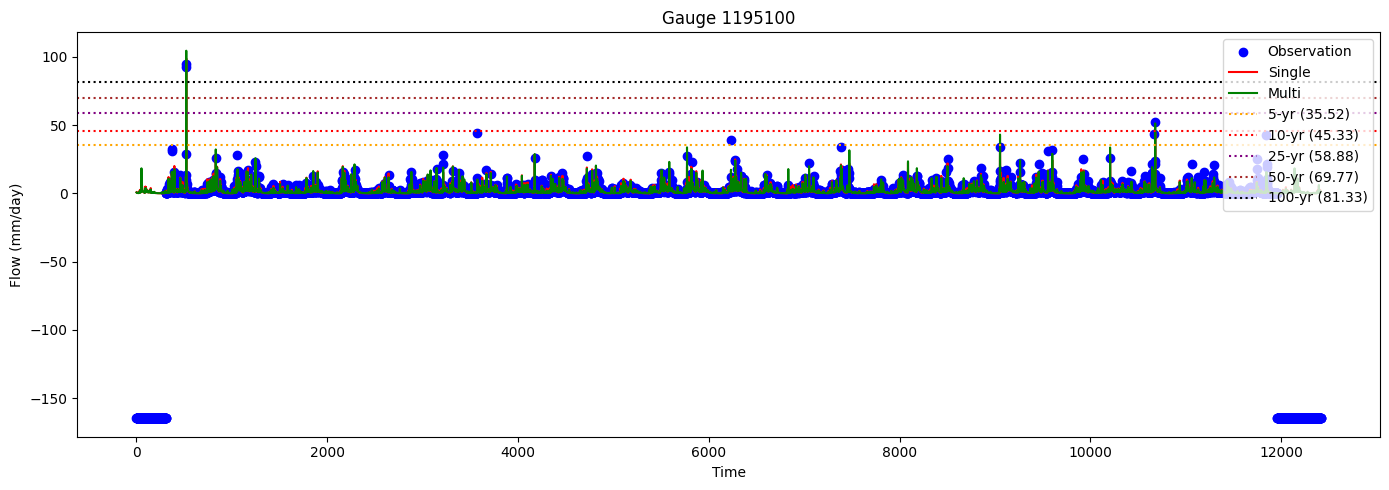

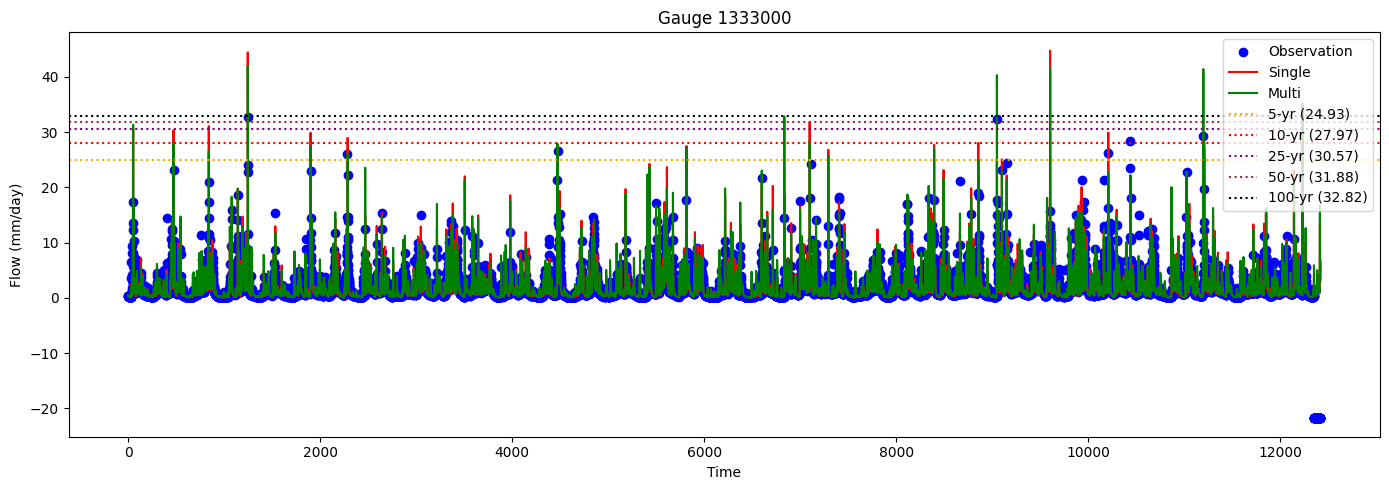

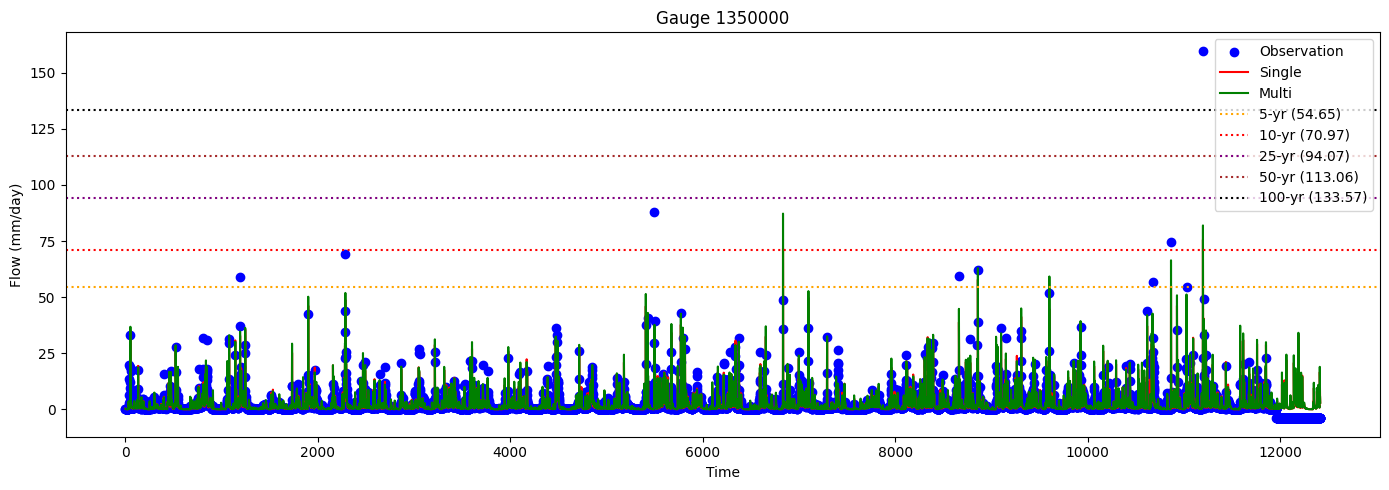

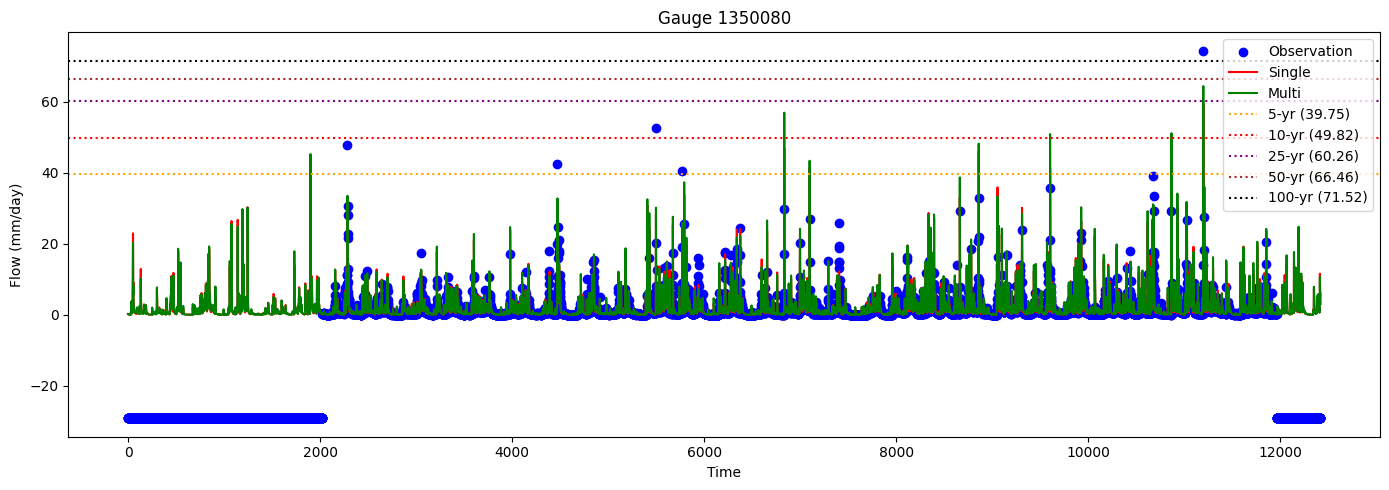

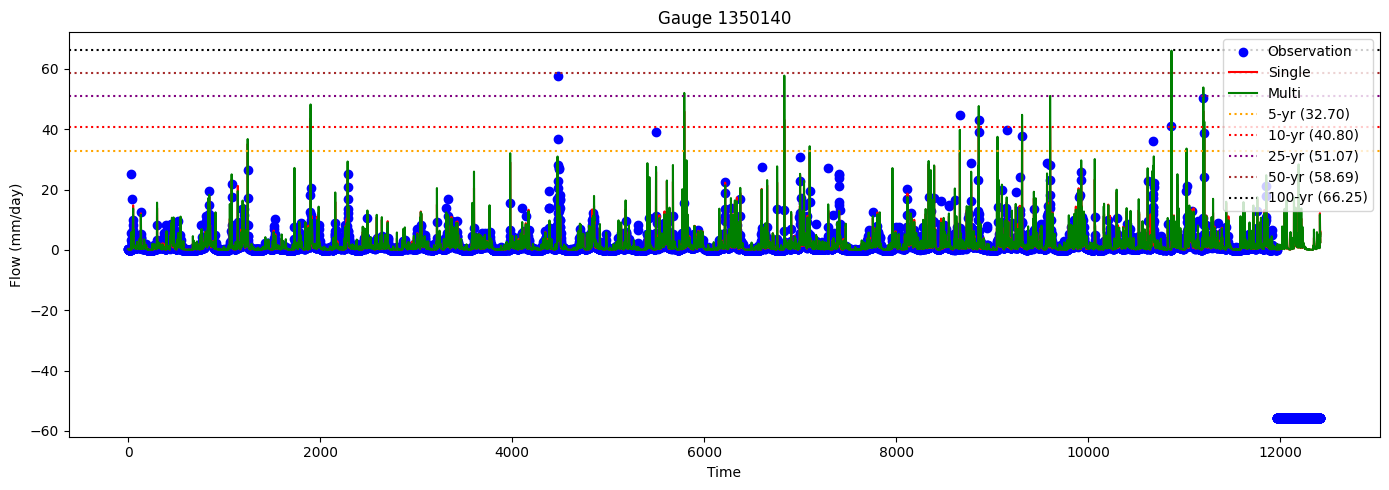

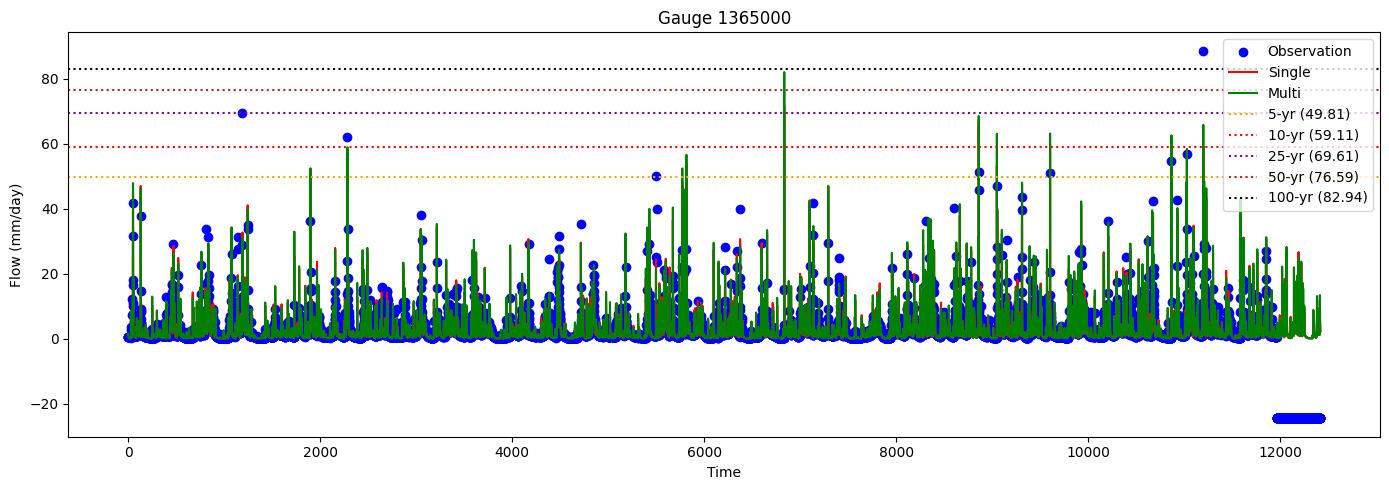

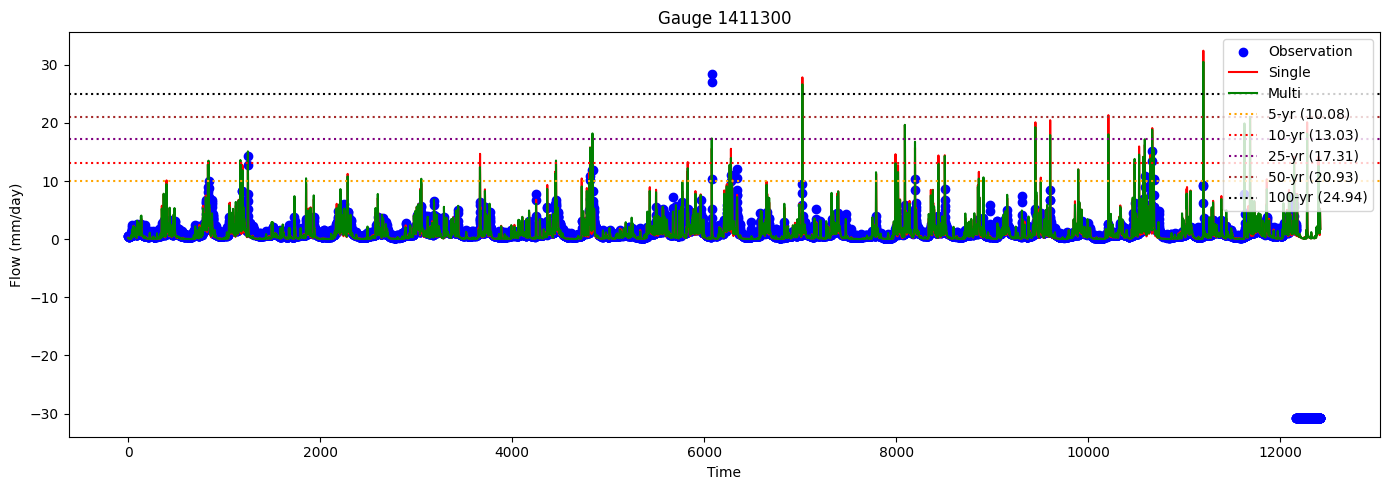

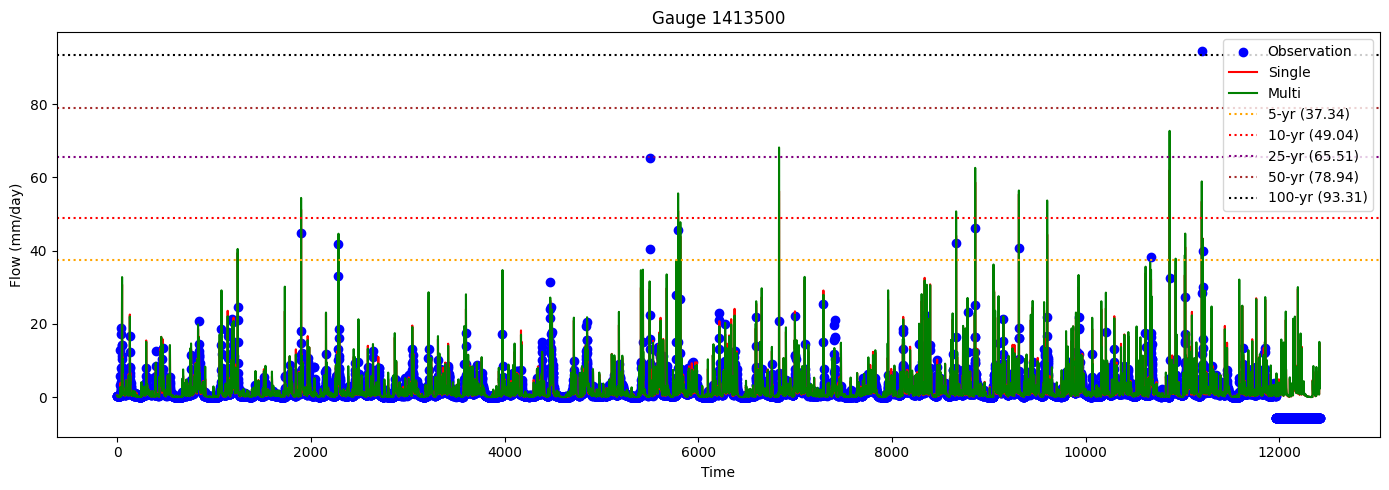

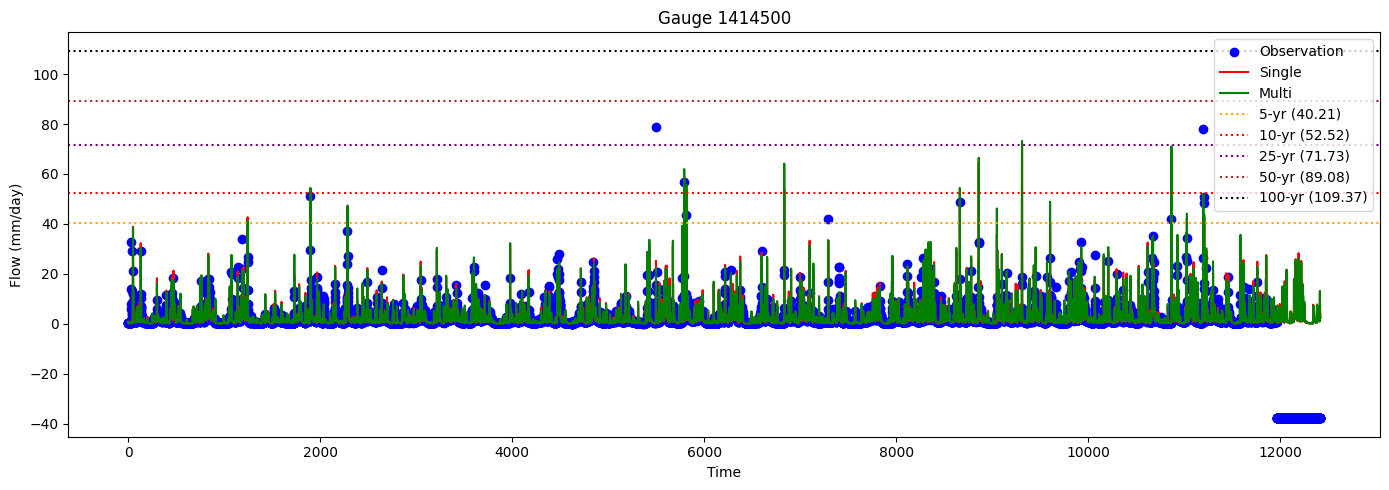

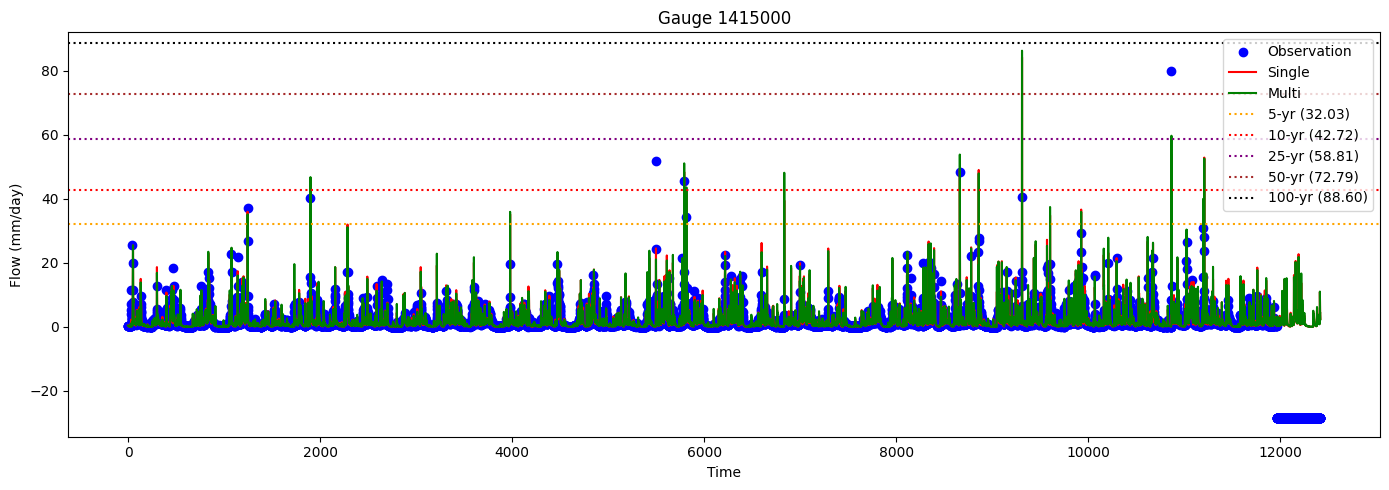

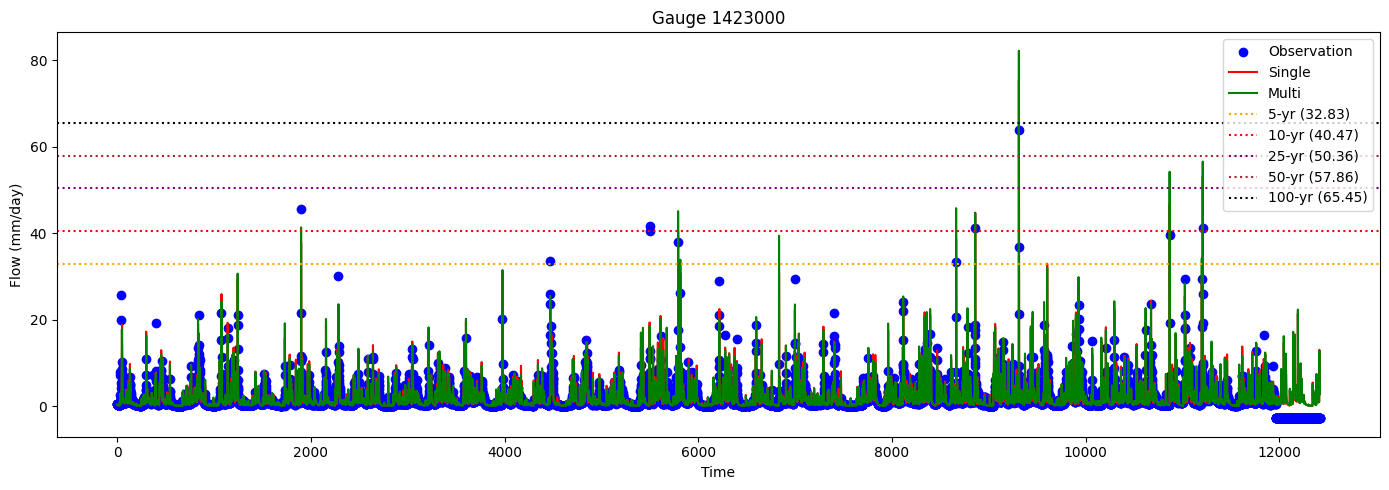

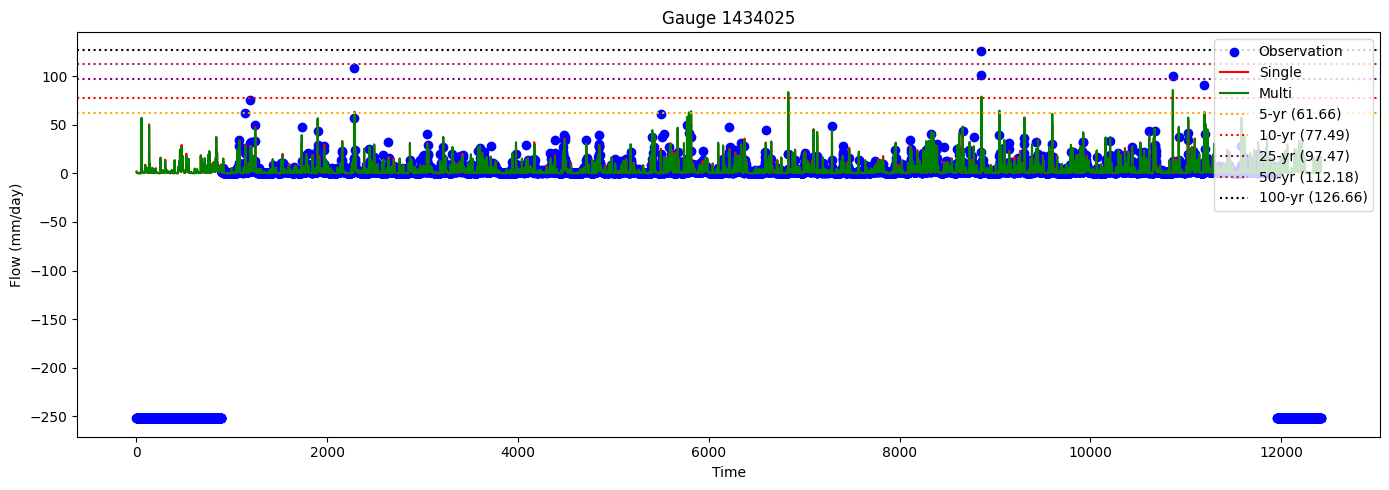

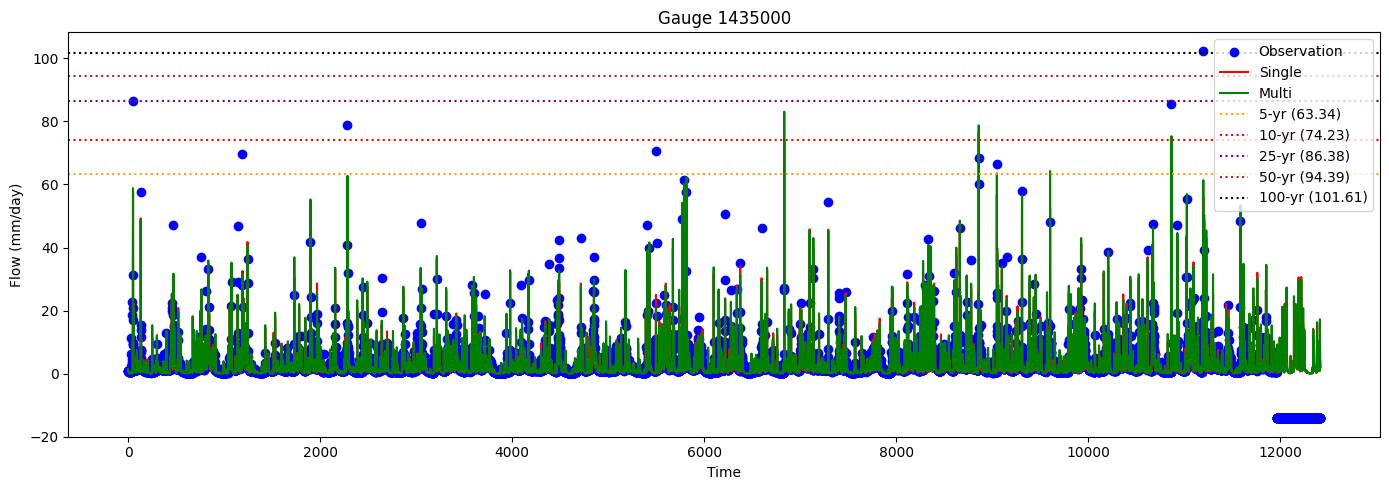

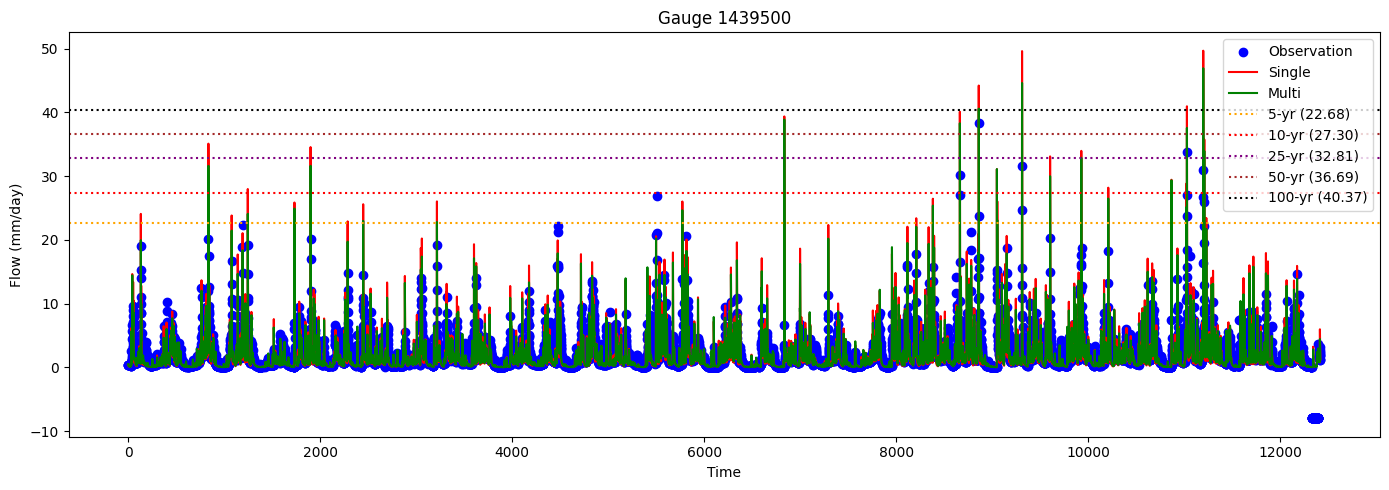

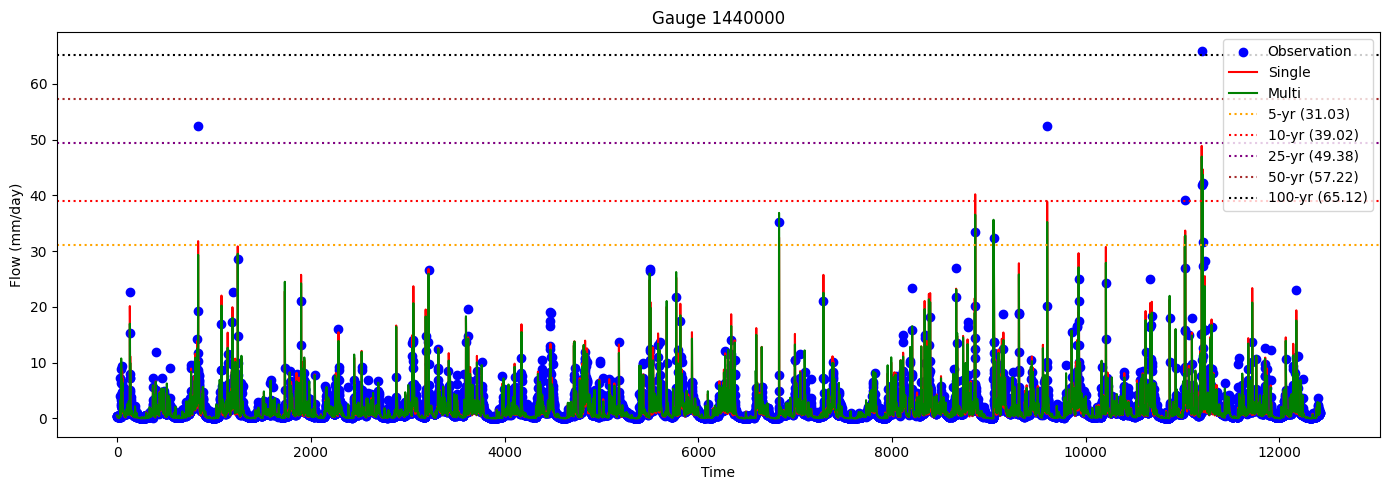

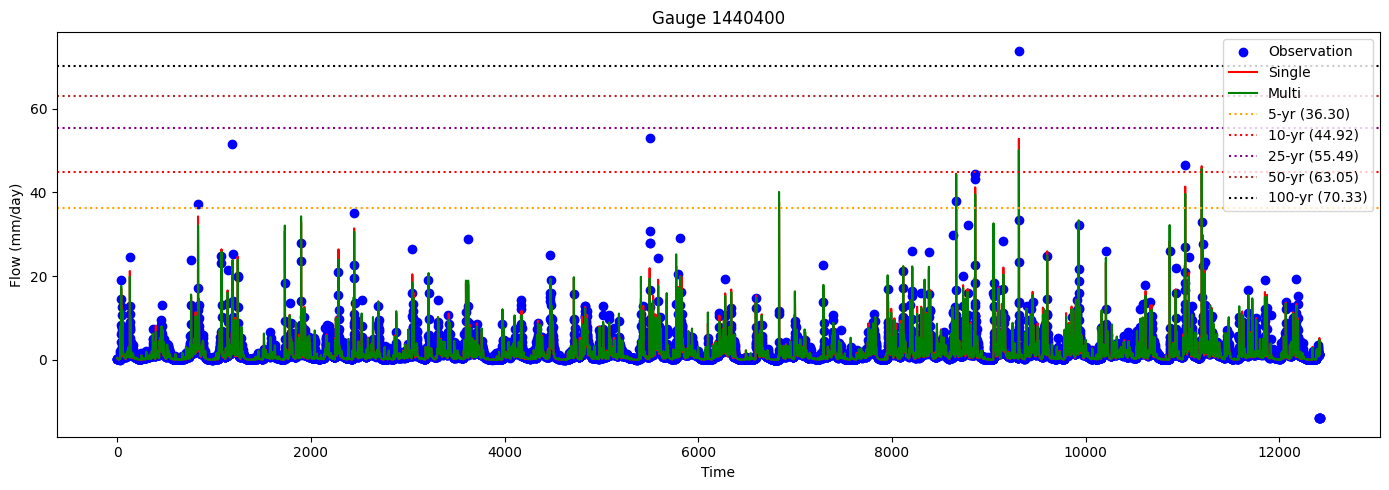

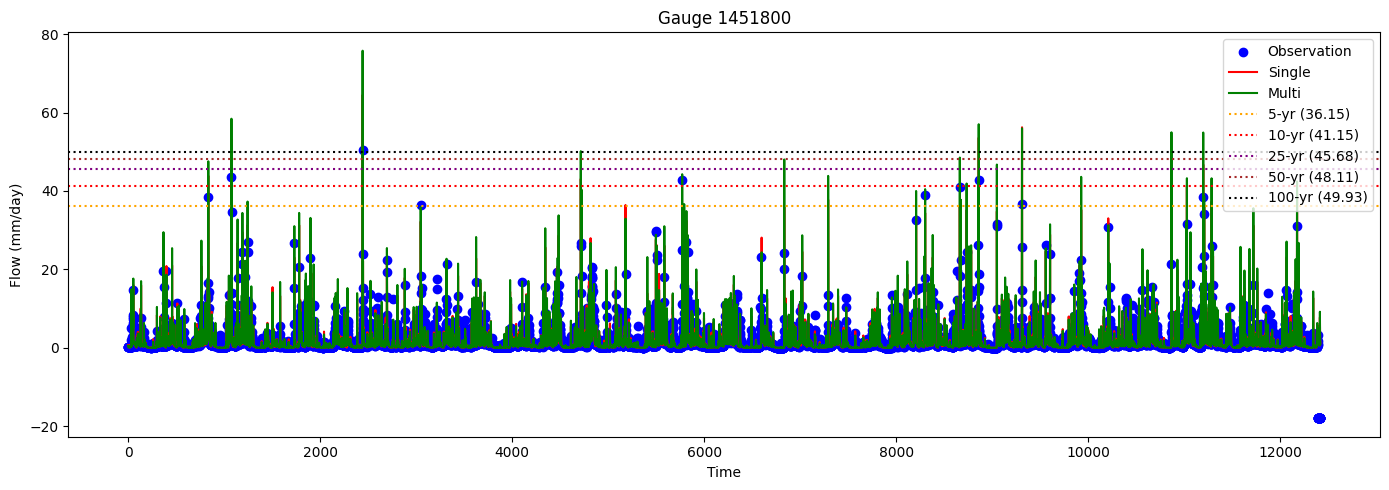

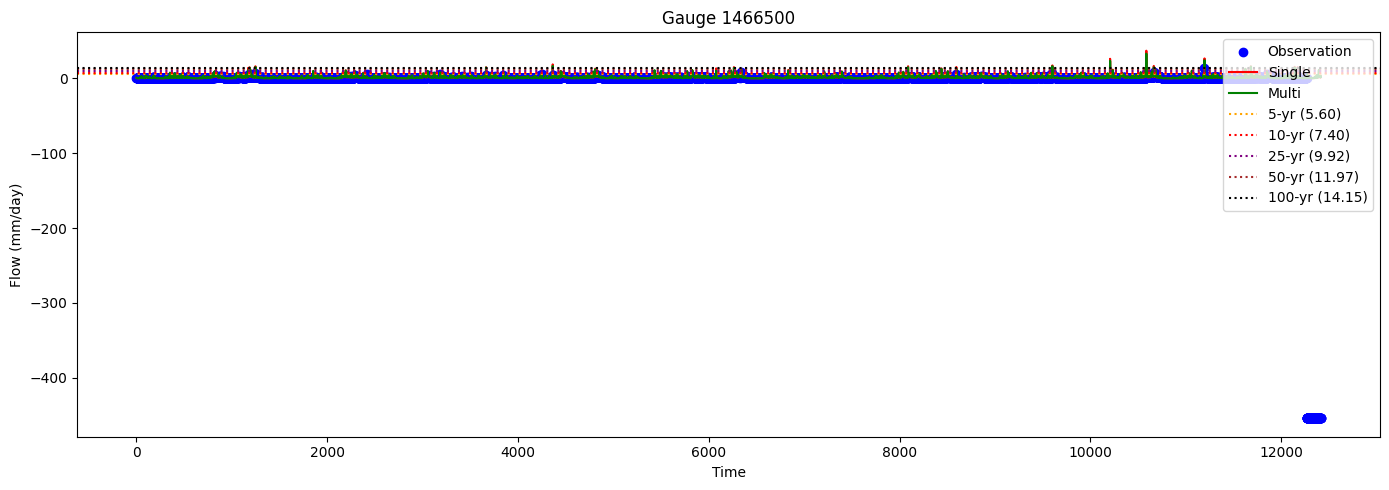

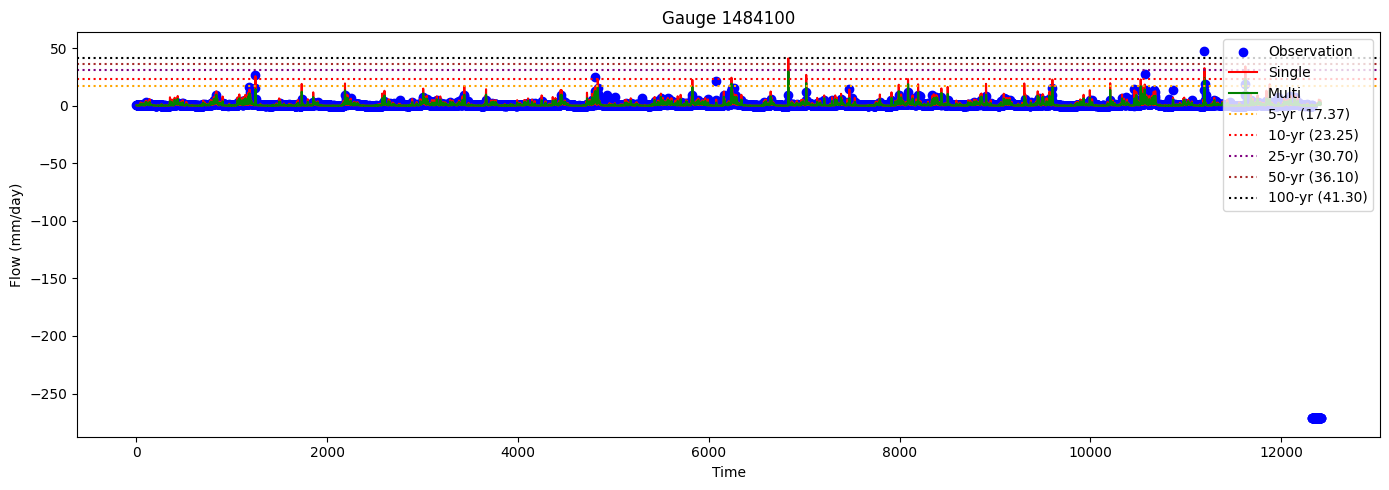

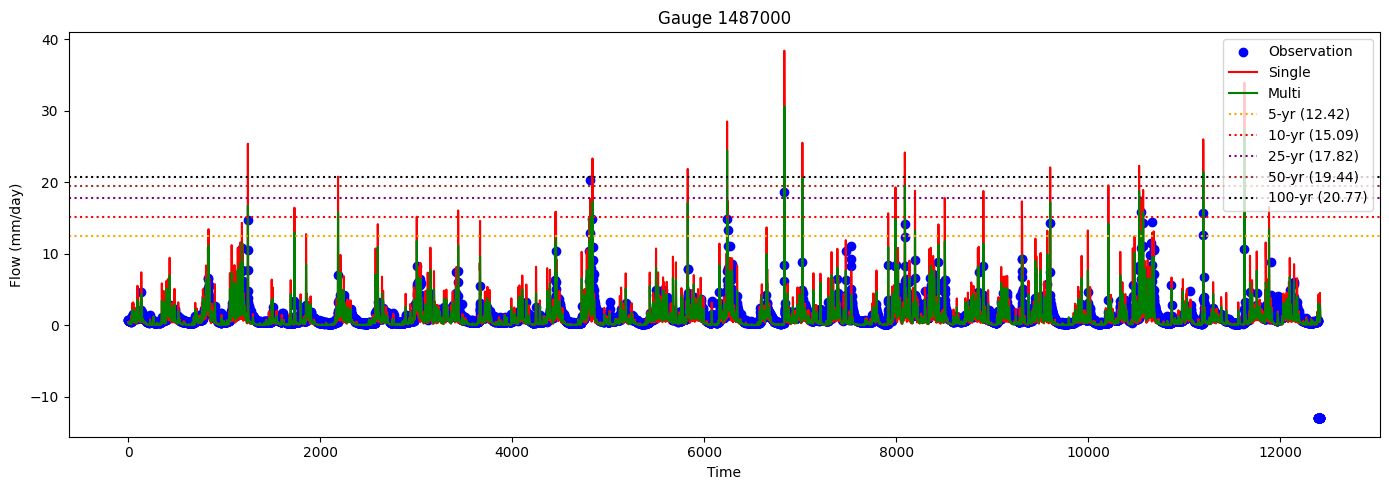

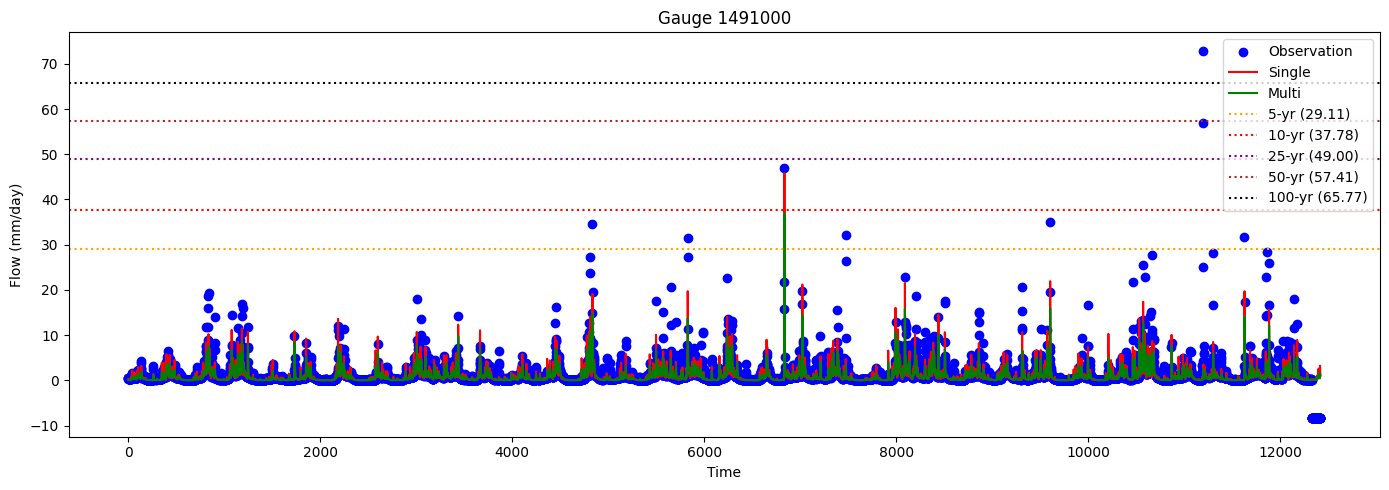

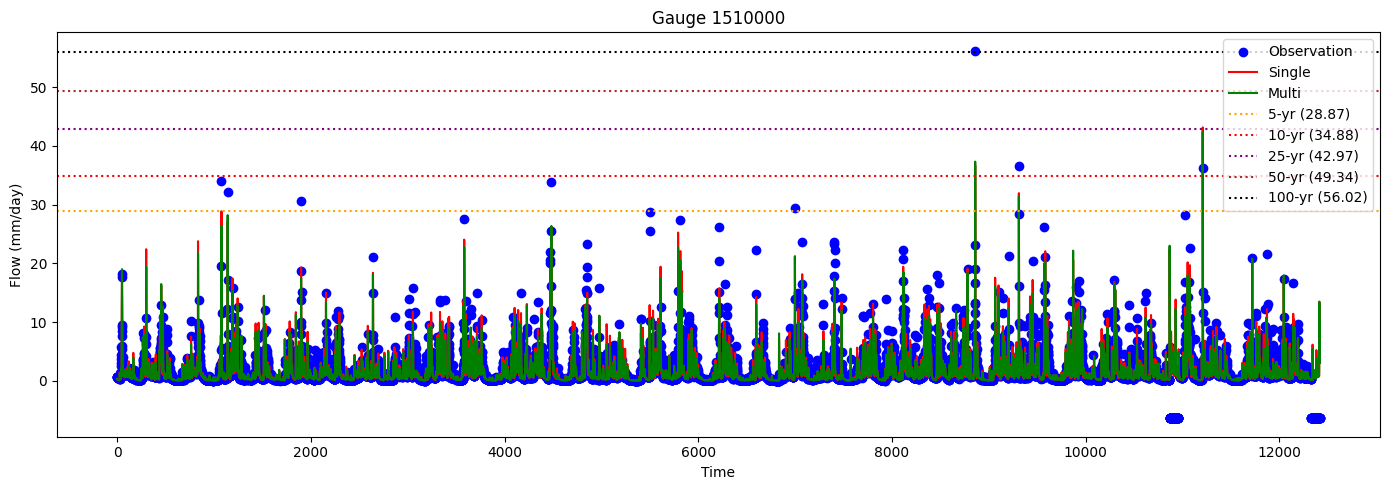

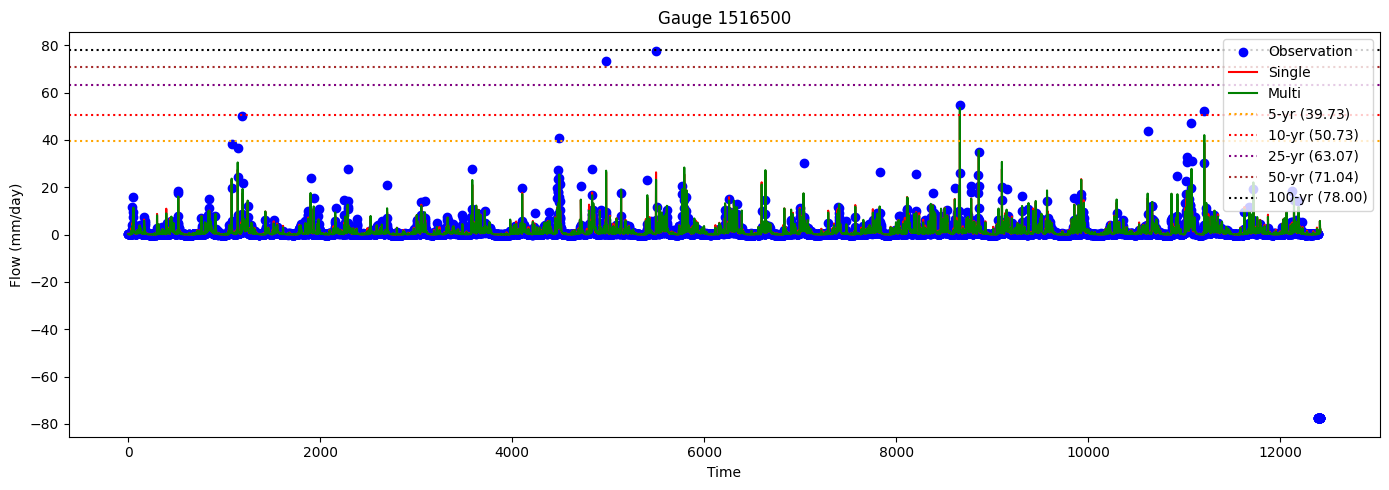

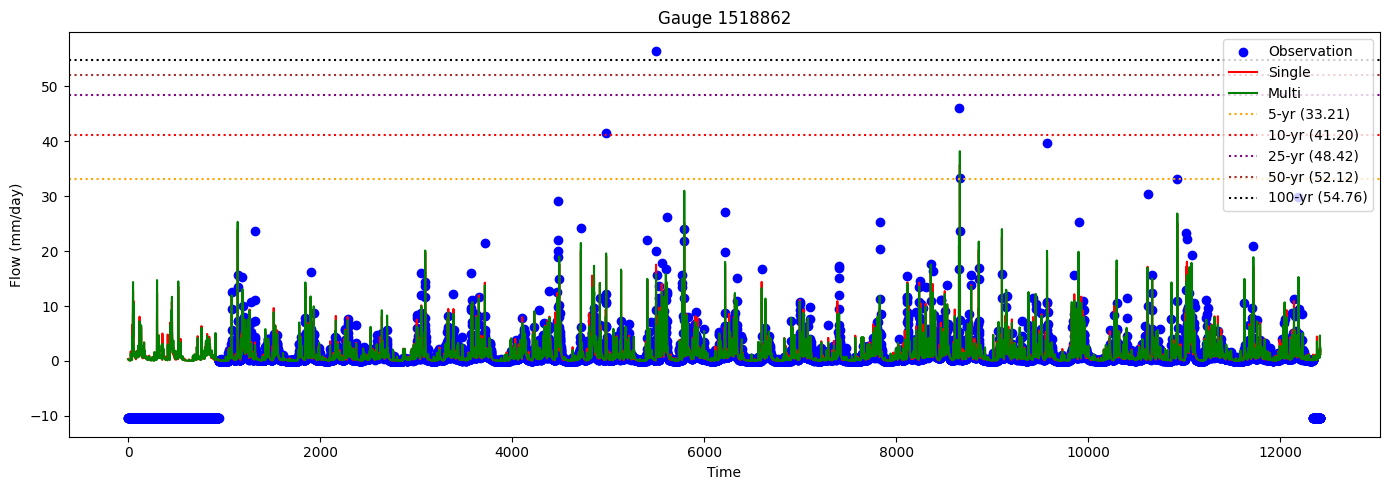

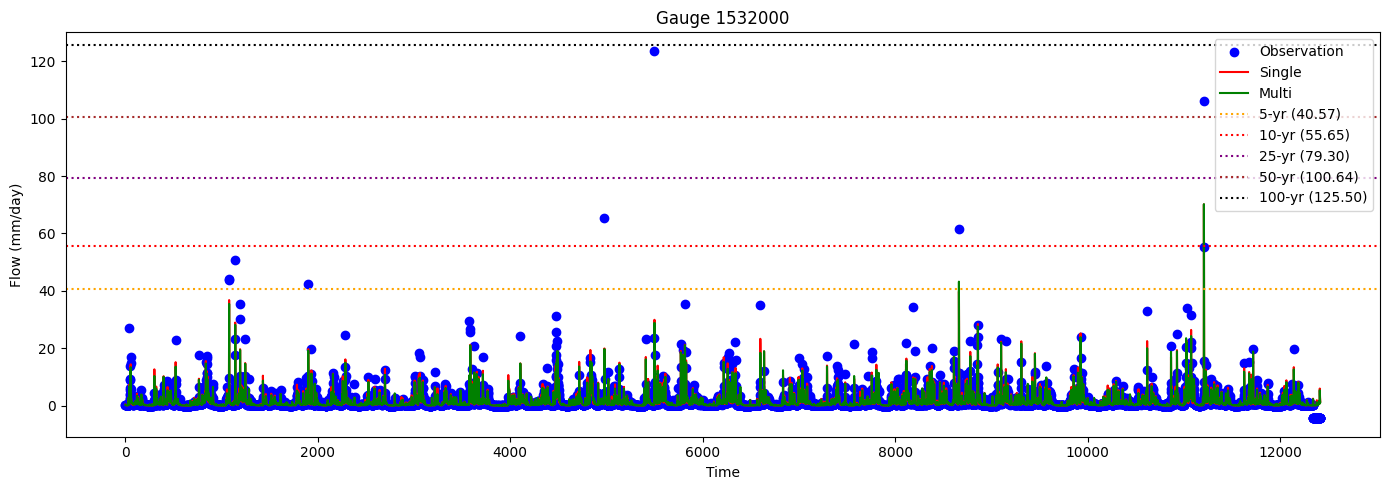

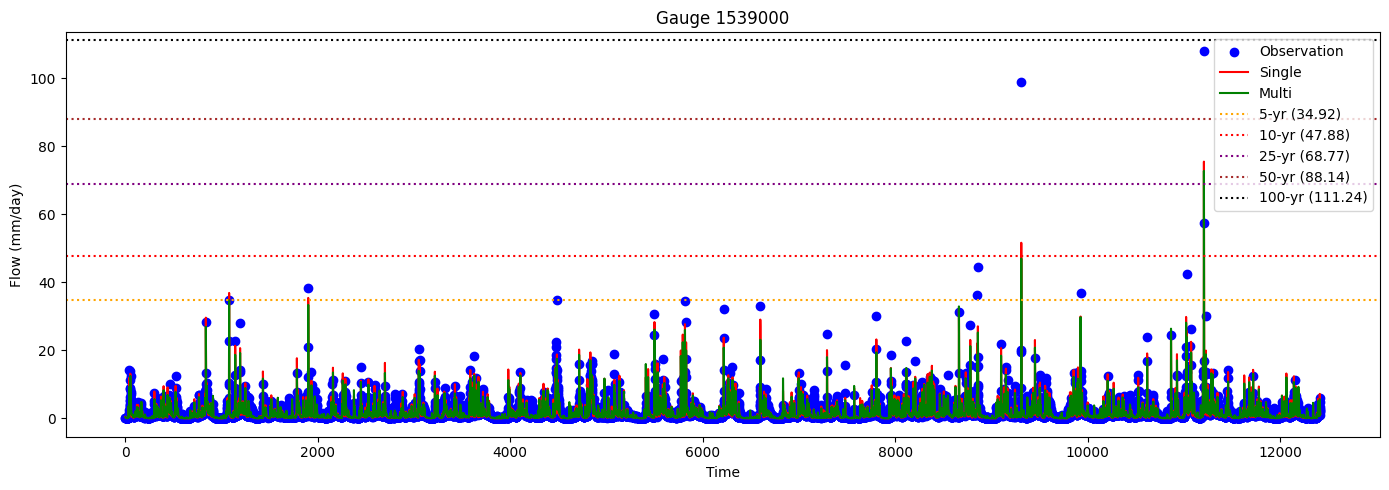

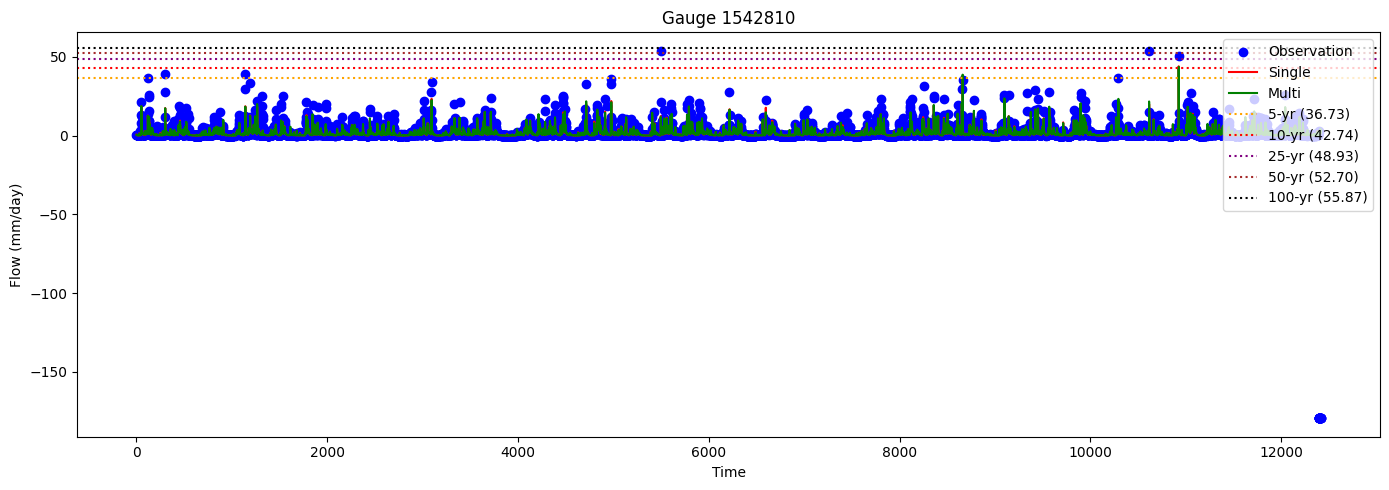

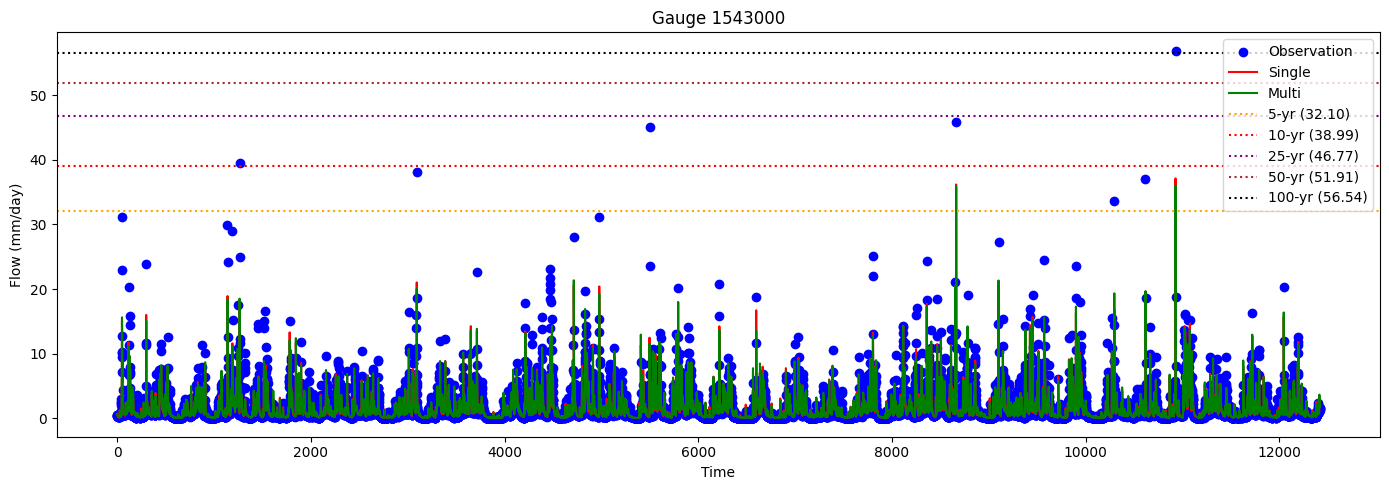

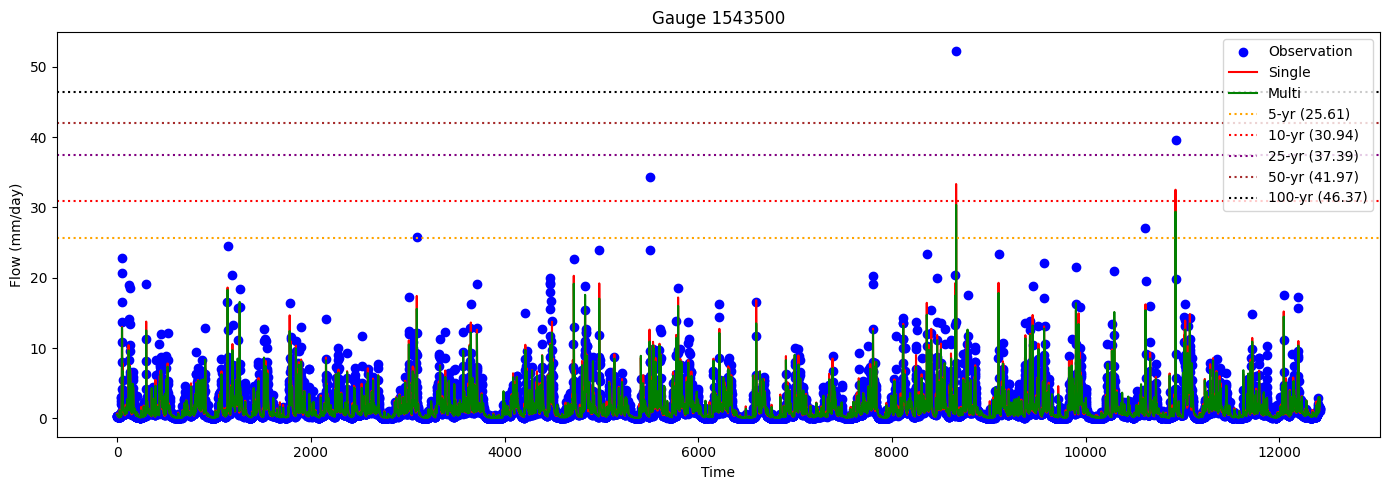

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

forcing = np.load(
    "/scratch/data/PUR_DATA/test/Region_1/daymet_19800101_20141231_forcing_671.npy"
)

gauge = forcing[:, 0, -1].astype(int)

threshold = pd.read_csv(
    "/scratch/data/CAMELS_FORCING/CAMELS_LP3_flood_thresholds_mmday.csv",
    index_col="Gauge_ID"
)

obs = np.load(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/00060_Mean.npy"
)

sims = np.load(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/OUTPUTS_PUR_Single/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
).squeeze()

simm = np.load(
    "/home/s0shar47/scratch/OUTPUTS_Paper1/PUR/Furey_Multi/Region_1/LSTM_HBV_E50_R365_B100_H256_tr1989_1999_n16_111111/parBETA_parBETAET_/ts1980_2014/flow_sim.npy"
).squeeze()

colors = {
    "Q_5yr": "orange",
    "Q_10yr": "red",
    "Q_25yr": "purple",
    "Q_50yr": "brown",
    "Q_100yr": "black",
}

for i in range(50):

    gauge_id = gauge[i]

    plt.figure(figsize=(14, 5))

    plt.scatter(range(obs.shape[0]),obs[:, i], label="Observation", color="blue")
    plt.plot(sims[:, i], label="Single", color="red")
    plt.plot(simm[:, i], label="Multi", color="green")

    # Plot threshold lines
    if gauge_id in threshold.index:

        for rp in [5, 10, 25, 50, 100]:

            value = threshold.loc[gauge_id, f"Q_{rp}yr"]

            if np.isfinite(value):
                plt.axhline(
                    value,
                    linestyle=":",
                    linewidth=1.5,
                    color=colors[f"Q_{rp}yr"],
                    label=f"{rp}-yr ({value:.2f})"
                )

    plt.title(f"Gauge {gauge_id}")
    plt.xlabel("Time")
    plt.ylabel("Flow (mm/day)")
    plt.legend(loc="upper right")
    plt.xlim()
    plt.tight_layout()
    plt.show()